<a href="https://www.kaggle.com/code/lalit7881/zoo-animal-classification-100?scriptVersionId=372927030" target="_blank"><img align="left" alt="Kaggle" title="Open in Kaggle" src="https://kaggle.com/static/images/open-in-kaggle.svg"></a>

In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")
# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/raghunathangrdr/zoo-data-dataset/zoo_data-1.csv


## Loading dataset

In [2]:
df = pd.read_csv("/kaggle/input/datasets/raghunathangrdr/zoo-data-dataset/zoo_data-1.csv")

In [3]:
df.head()

,animal_name,hair,feathers,eggs,milk,airborne,aquatic,predator,toothed,backbone,breathes,venomous,fins,legs,tail,domestic,catsize
0,aardvark,1,0,0,1,0,0,1,1,1,1,0,0,4,0,0,1
1,antelope,1,0,0,1,0,0,0,1,1,1,0,0,4,1,0,1
2,bass,0,0,1,0,0,1,1,1,1,0,0,1,0,1,0,0
3,bear,1,0,0,1,0,0,1,1,1,1,0,0,4,0,0,1
4,boar,1,0,0,1,0,0,1,1,1,1,0,0,4,1,0,1


In [4]:
df.tail()

,animal_name,hair,feathers,eggs,milk,airborne,aquatic,predator,toothed,backbone,breathes,venomous,fins,legs,tail,domestic,catsize
96,wallaby,1,0,0,1,0,0,0,1,1,1,0,0,2,1,0,1
97,wasp,1,0,1,0,1,0,0,0,0,1,1,0,6,0,0,0
98,wolf,1,0,0,1,0,0,1,1,1,1,0,0,4,1,0,1
99,worm,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,0
100,wren,0,1,1,0,1,0,0,0,1,1,0,0,2,1,0,0


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 101 entries, 0 to 100
Data columns (total 17 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   animal_name  101 non-null    object
 1   hair         101 non-null    int64 
 2   feathers     101 non-null    int64 
 3   eggs         101 non-null    int64 
 4   milk         101 non-null    int64 
 5   airborne     101 non-null    int64 
 6   aquatic      101 non-null    int64 
 7   predator     101 non-null    int64 
 8   toothed      101 non-null    int64 
 9   backbone     101 non-null    int64 
 10  breathes     101 non-null    int64 
 11  venomous     101 non-null    int64 
 12  fins         101 non-null    int64 
 13  legs         101 non-null    int64 
 14  tail         101 non-null    int64 
 15  domestic     101 non-null    int64 
 16  catsize      101 non-null    int64 
dtypes: int64(16), object(1)
memory usage: 13.5+ KB


In [6]:
df.describe()

,hair,feathers,eggs,milk,airborne,aquatic,predator,toothed,backbone,breathes,venomous,fins,legs,tail,domestic,catsize
count,101.000000,101.000000,101.000000,101.000000,101.000000,101.000000,101.000000,101.000000,101.000000,101.000000,101.000000,101.000000,101.000000,101.000000,101.000000,101.000000
mean,0.425743,0.198020,0.584158,0.405941,0.237624,0.356436,0.554455,0.603960,0.821782,0.792079,0.079208,0.168317,2.841584,0.742574,0.128713,0.435644
std,0.496921,0.400495,0.495325,0.493522,0.427750,0.481335,0.499505,0.491512,0.384605,0.407844,0.271410,0.376013,2.033385,0.439397,0.336552,0.498314
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,0.000000,0.000000,2.000000,0.000000,0.000000,0.000000
50%,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000,1.000000,1.000000,1.000000,0.000000,0.000000,4.000000,1.000000,0.000000,0.000000
75%,1.000000,0.000000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,0.000000,4.000000,1.000000,0.000000,1.000000
max,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,8.000000,1.000000,1.000000,1.000000


In [7]:
df.isnull().sum()

animal_name    0
hair           0
feathers       0
eggs           0
milk           0
airborne       0
aquatic        0
predator       0
toothed        0
backbone       0
breathes       0
venomous       0
fins           0
legs           0
tail           0
domestic       0
catsize        0
dtype: int64

In [8]:
df.duplicated().sum()

np.int64(0)

In [9]:
df.dtypes

animal_name    object
hair            int64
feathers        int64
eggs            int64
milk            int64
airborne        int64
aquatic         int64
predator        int64
toothed         int64
backbone        int64
breathes        int64
venomous        int64
fins            int64
legs            int64
tail            int64
domestic        int64
catsize         int64
dtype: object

In [10]:
df.shape

(101, 17)

In [11]:
df.columns

Index(['animal_name', 'hair', 'feathers', 'eggs', 'milk', 'airborne',
       'aquatic', 'predator', 'toothed', 'backbone', 'breathes', 'venomous',
       'fins', 'legs', 'tail', 'domestic', 'catsize'],
      dtype='object')

In [12]:
df.nunique()

animal_name    100
hair             2
feathers         2
eggs             2
milk             2
airborne         2
aquatic          2
predator         2
toothed          2
backbone         2
breathes         2
venomous         2
fins             2
legs             6
tail             2
domestic         2
catsize          2
dtype: int64

## EDA

DATASET OVERVIEW

First 5 Rows:


,animal_name,hair,feathers,eggs,milk,airborne,aquatic,predator,toothed,backbone,breathes,venomous,fins,legs,tail,domestic,catsize
0,aardvark,1,0,0,1,0,0,1,1,1,1,0,0,4,0,0,1
1,antelope,1,0,0,1,0,0,0,1,1,1,0,0,4,1,0,1
2,bass,0,0,1,0,0,1,1,1,1,0,0,1,0,1,0,0
3,bear,1,0,0,1,0,0,1,1,1,1,0,0,4,0,0,1
4,boar,1,0,0,1,0,0,1,1,1,1,0,0,4,1,0,1



Last 5 Rows:


,animal_name,hair,feathers,eggs,milk,airborne,aquatic,predator,toothed,backbone,breathes,venomous,fins,legs,tail,domestic,catsize
96,wallaby,1,0,0,1,0,0,0,1,1,1,0,0,2,1,0,1
97,wasp,1,0,1,0,1,0,0,0,0,1,1,0,6,0,0,0
98,wolf,1,0,0,1,0,0,1,1,1,1,0,0,4,1,0,1
99,worm,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,0
100,wren,0,1,1,0,1,0,0,0,1,1,0,0,2,1,0,0



Dataset Shape: (101, 17)

Column Names:
['animal_name', 'hair', 'feathers', 'eggs', 'milk', 'airborne', 'aquatic', 'predator', 'toothed', 'backbone', 'breathes', 'venomous', 'fins', 'legs', 'tail', 'domestic', 'catsize']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 101 entries, 0 to 100
Data columns (total 17 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   animal_name  101 non-null    object
 1   hair         101 non-null    int64 
 2   feathers     101 non-null    int64 
 3   eggs         101 non-null    int64 
 4   milk         101 non-null    int64 
 5   airborne     101 non-null    int64 
 6   aquatic      101 non-null    int64 
 7   predator     101 non-null    int64 
 8   toothed      101 non-null    int64 
 9   backbone     101 non-null    int64 
 10  breathes     101 non-null    int64 
 11  venomous     101 non-null    int64 
 12  fins         101 non-null    int64 
 13  legs         101 non-null    in

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
animal_name,101,100,frog,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
hair,101.0,NaN,NaN,NaN,0.425743,0.496921,0.0,0.0,0.0,1.0,1.0
feathers,101.0,NaN,NaN,NaN,0.19802,0.400495,0.0,0.0,0.0,0.0,1.0
eggs,101.0,NaN,NaN,NaN,0.584158,0.495325,0.0,0.0,1.0,1.0,1.0
milk,101.0,NaN,NaN,NaN,0.405941,0.493522,0.0,0.0,0.0,1.0,1.0
airborne,101.0,NaN,NaN,NaN,0.237624,0.42775,0.0,0.0,0.0,0.0,1.0
aquatic,101.0,NaN,NaN,NaN,0.356436,0.481335,0.0,0.0,0.0,1.0,1.0
predator,101.0,NaN,NaN,NaN,0.554455,0.499505,0.0,0.0,1.0,1.0,1.0
toothed,101.0,NaN,NaN,NaN,0.60396,0.491512,0.0,0.0,1.0,1.0,1.0
backbone,101.0,NaN,NaN,NaN,0.821782,0.384605,0.0,1.0,1.0,1.0,1.0



Missing Values:
animal_name    0
hair           0
feathers       0
eggs           0
milk           0
airborne       0
aquatic        0
predator       0
toothed        0
backbone       0
breathes       0
venomous       0
fins           0
legs           0
tail           0
domestic       0
catsize        0
dtype: int64

Total Missing Values: 0

Duplicate Records: 0

Unique Values:
animal_name    100
hair             2
feathers         2
eggs             2
milk             2
airborne         2
aquatic          2
predator         2
toothed          2
backbone         2
breathes         2
venomous         2
fins             2
legs             6
tail             2
domestic         2
catsize          2
dtype: int64


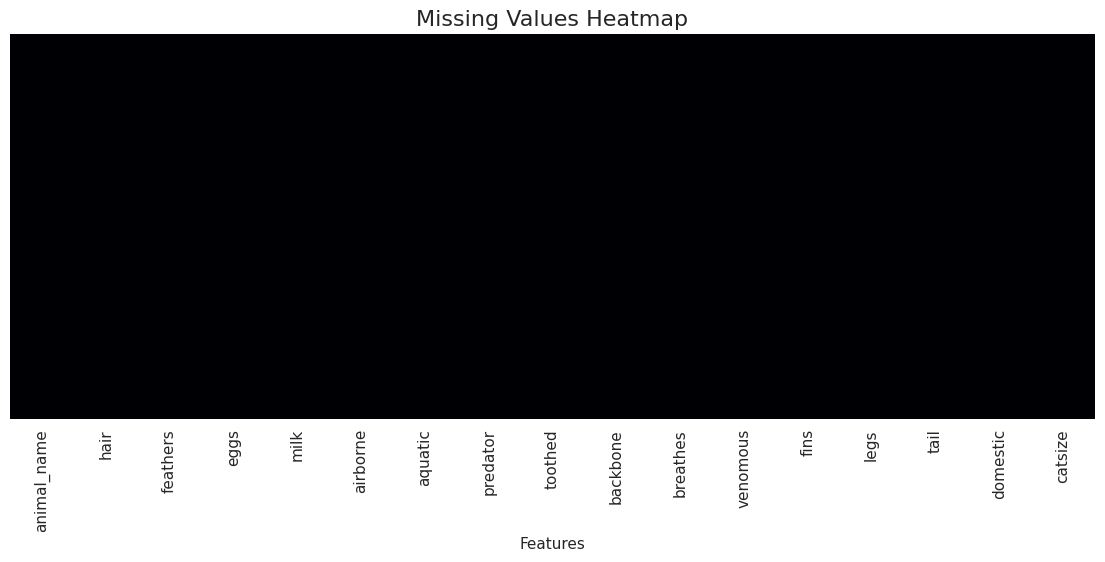

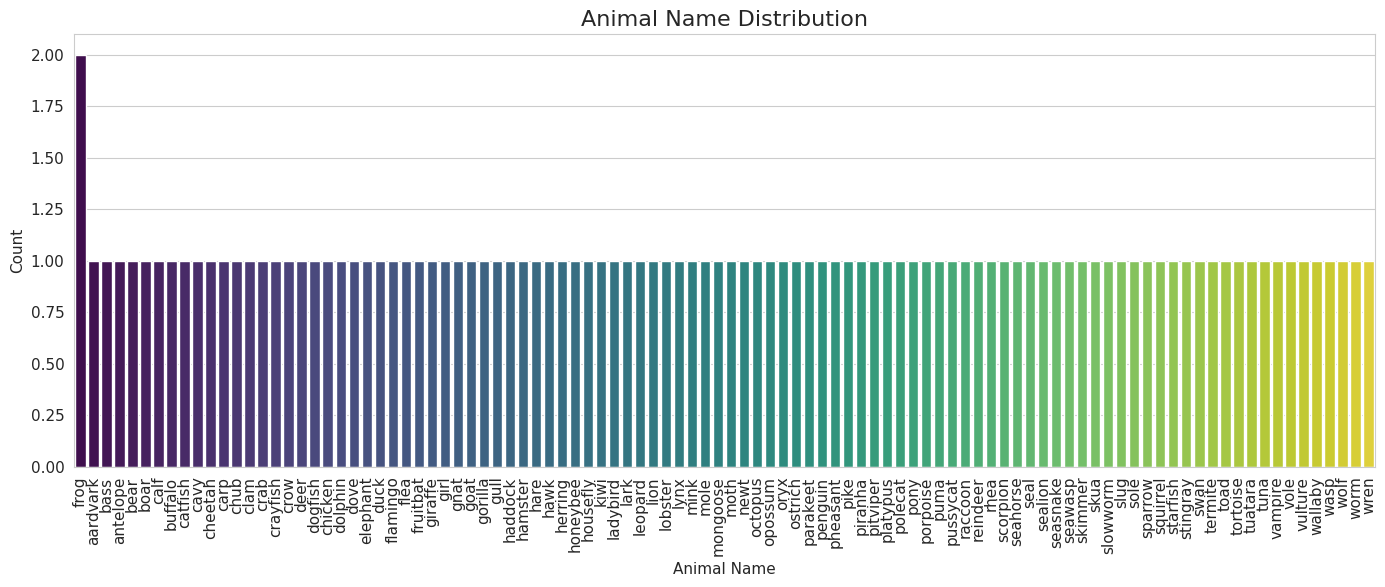

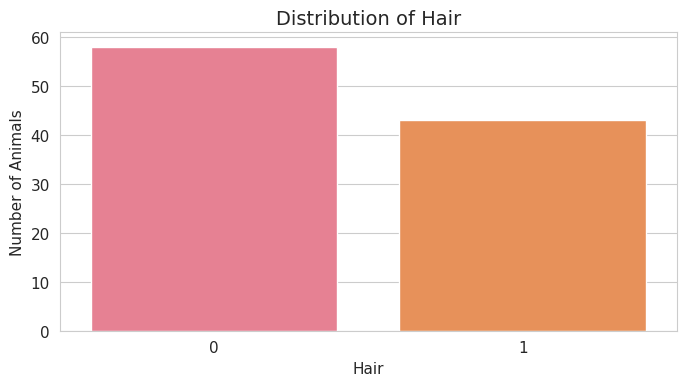

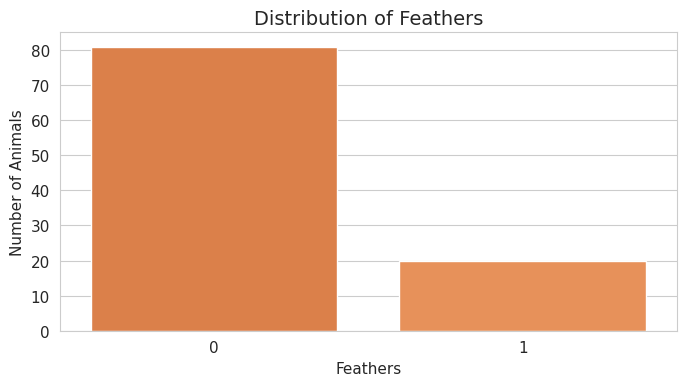

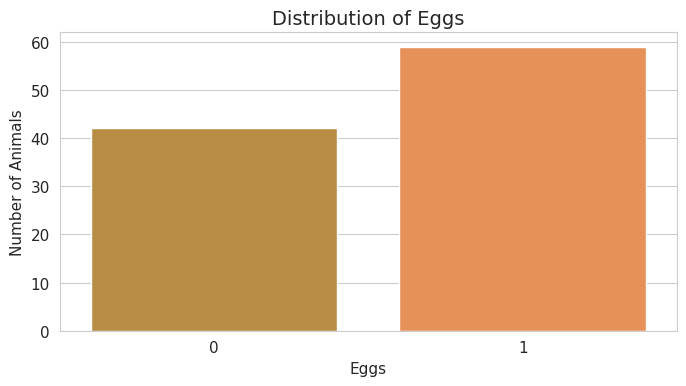

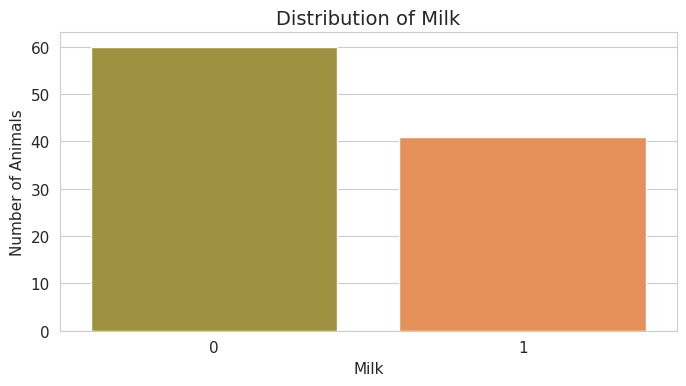

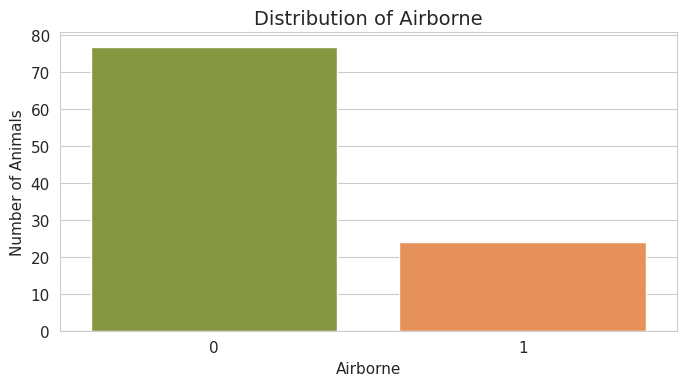

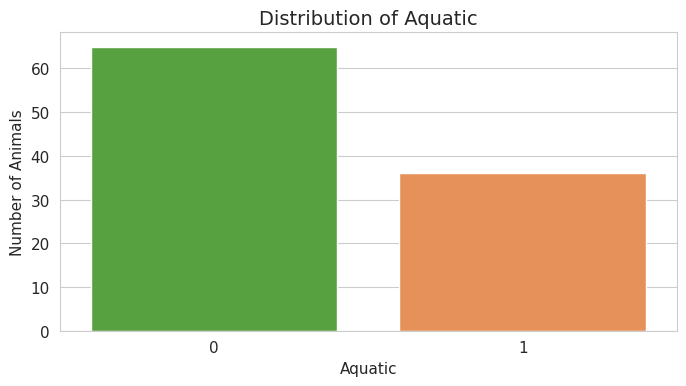

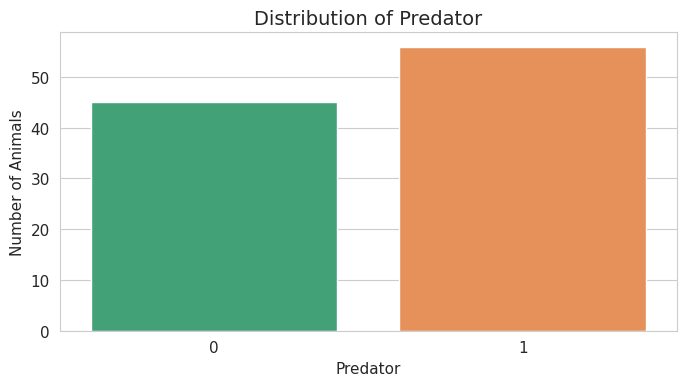

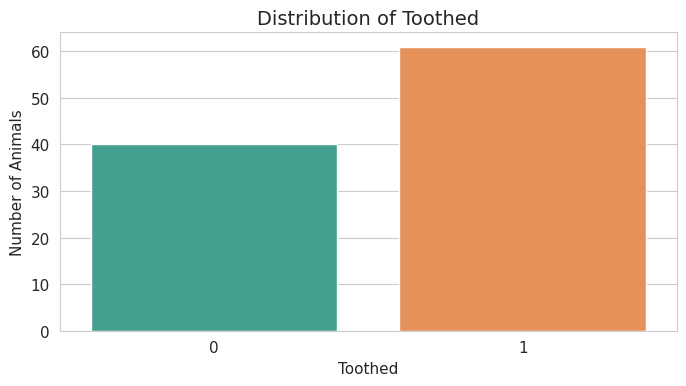

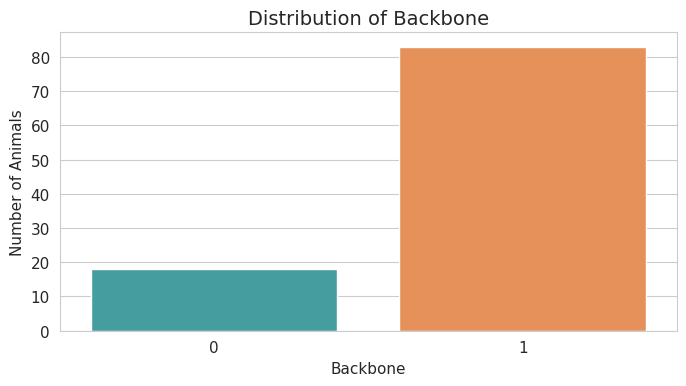

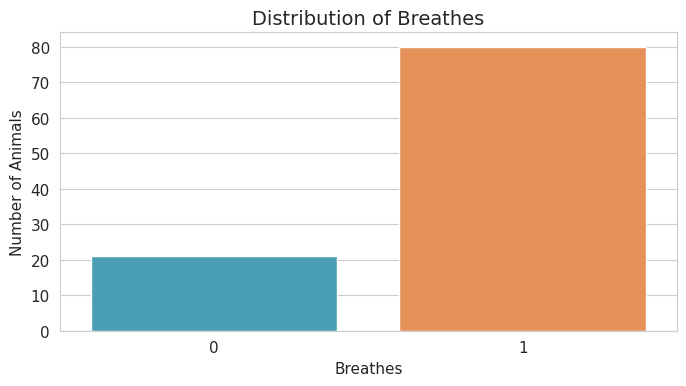

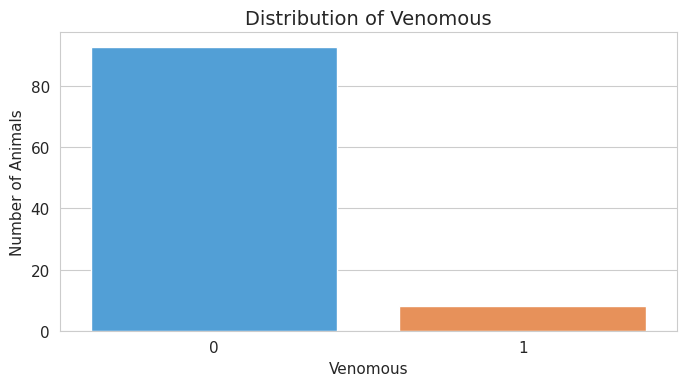

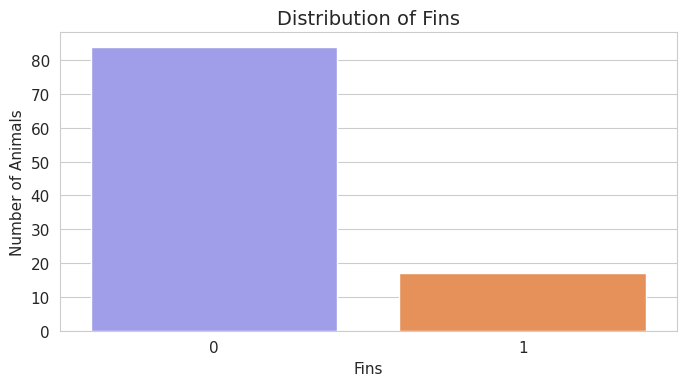

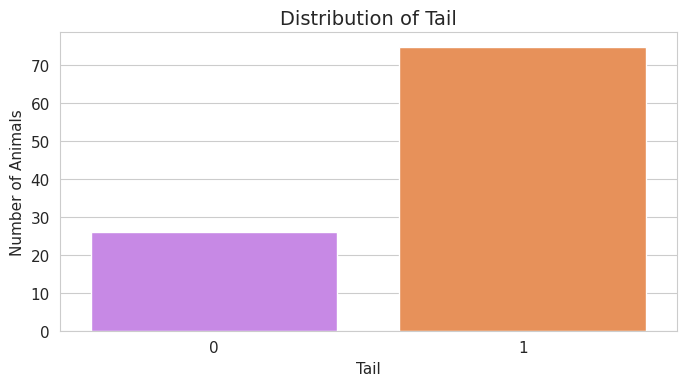

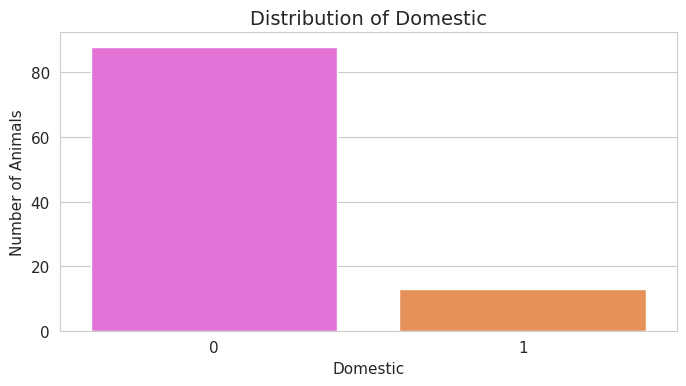

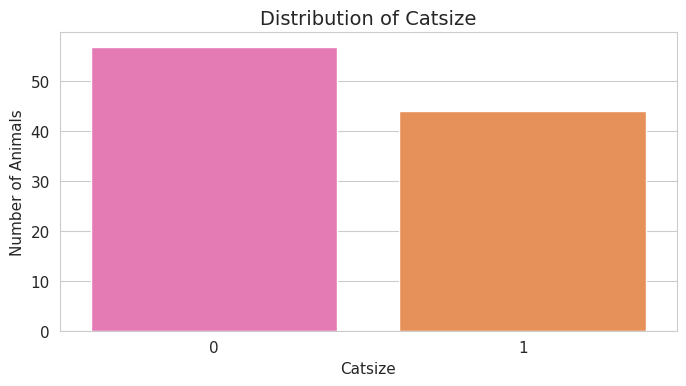

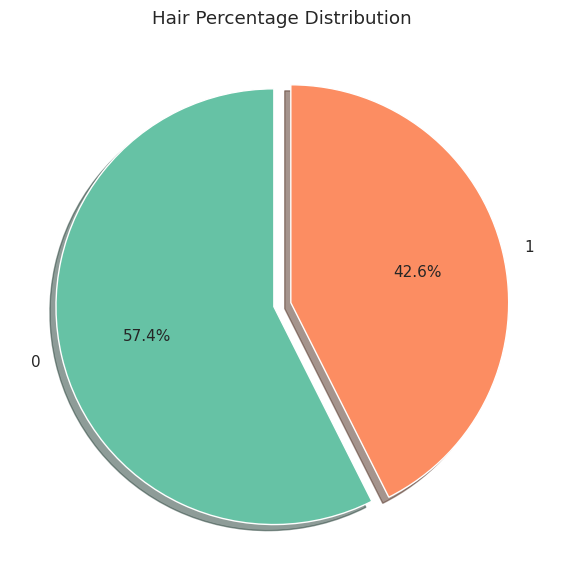

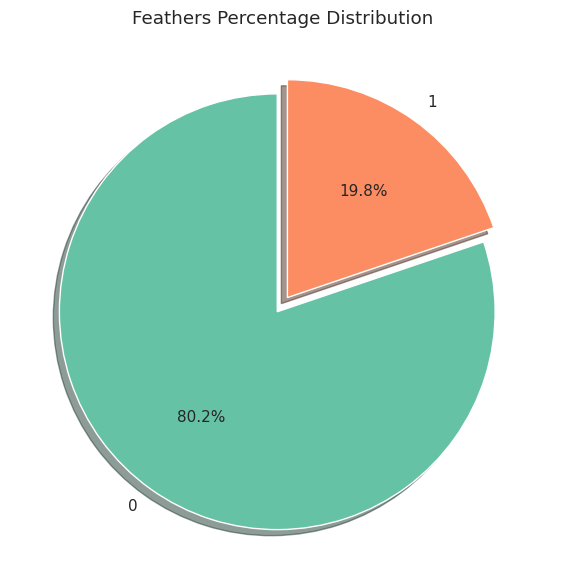

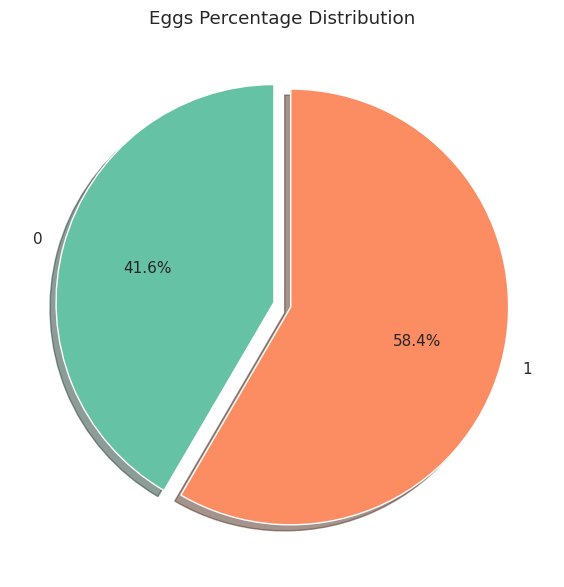

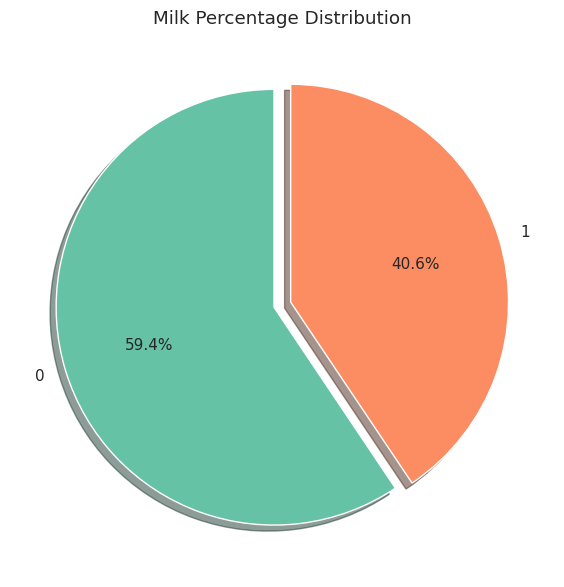

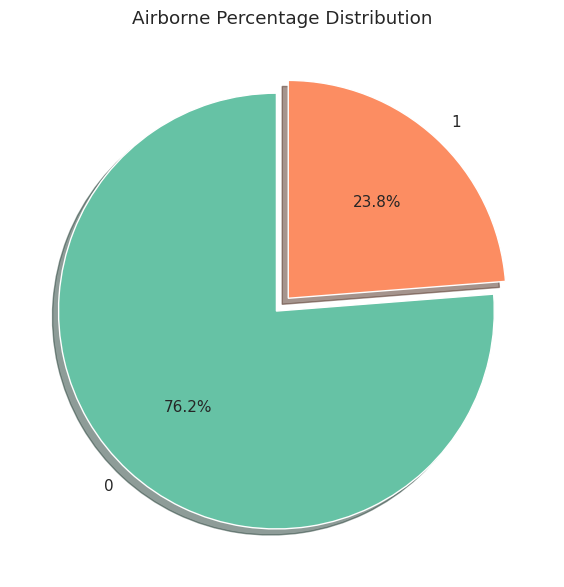

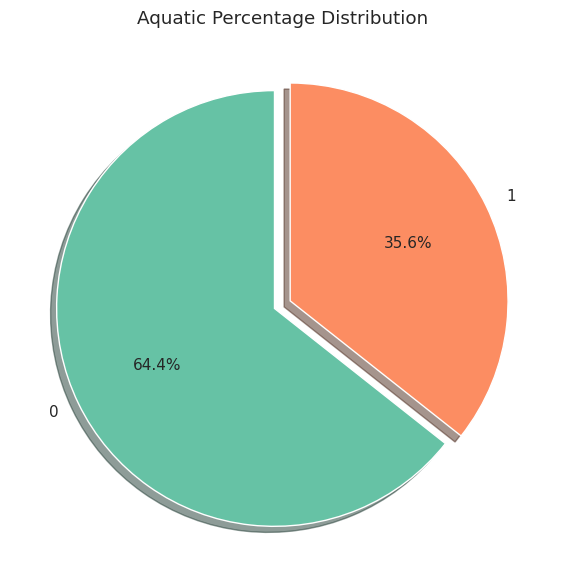

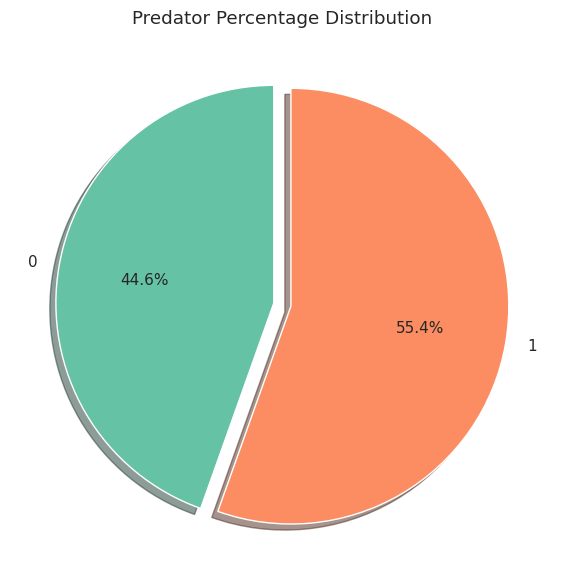

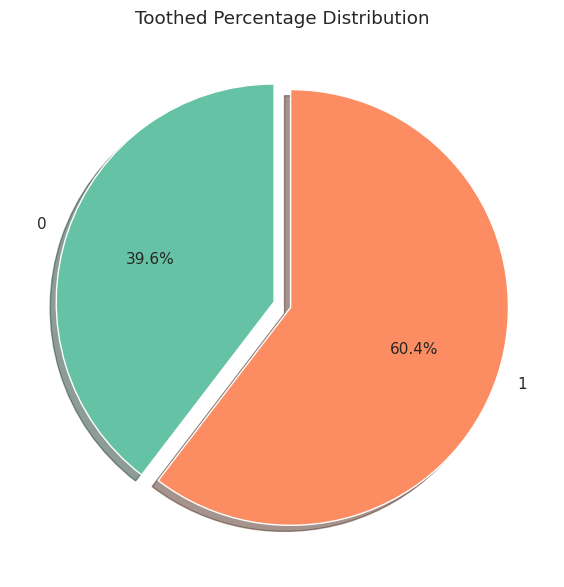

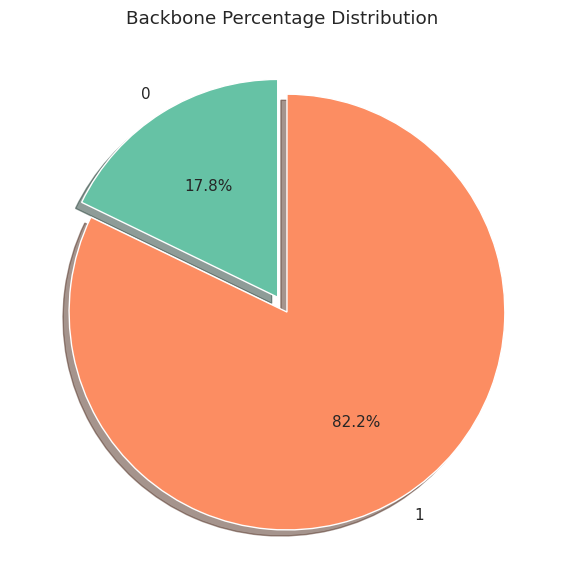

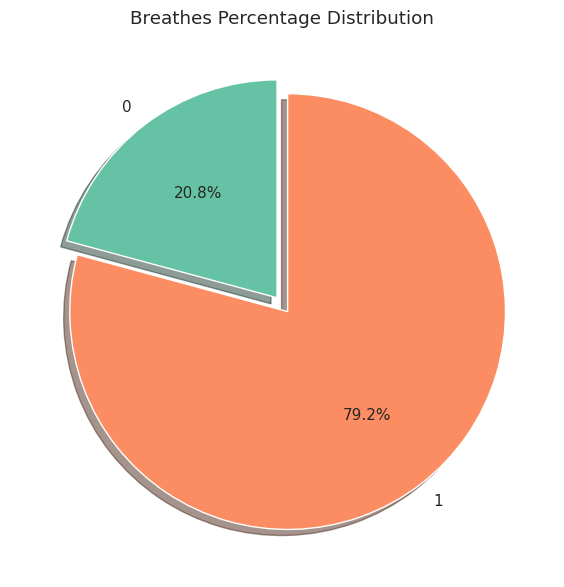

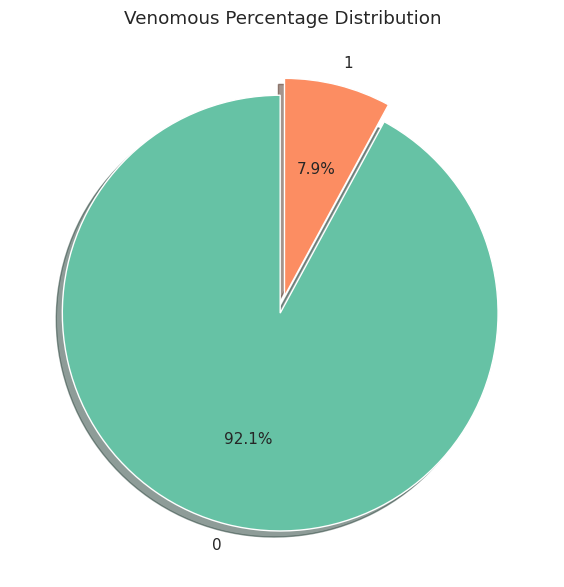

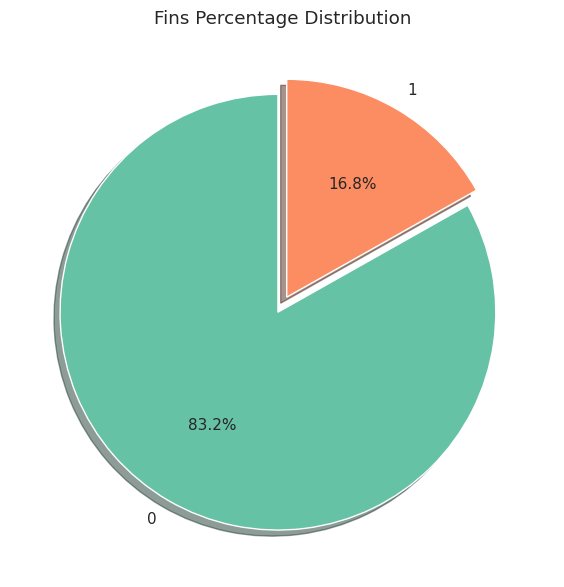

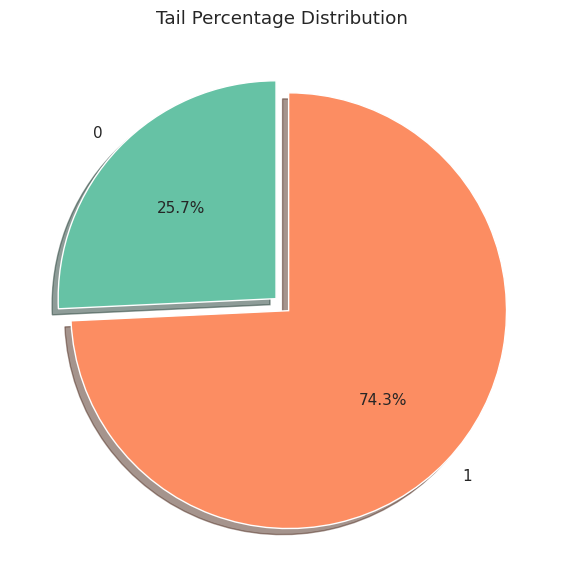

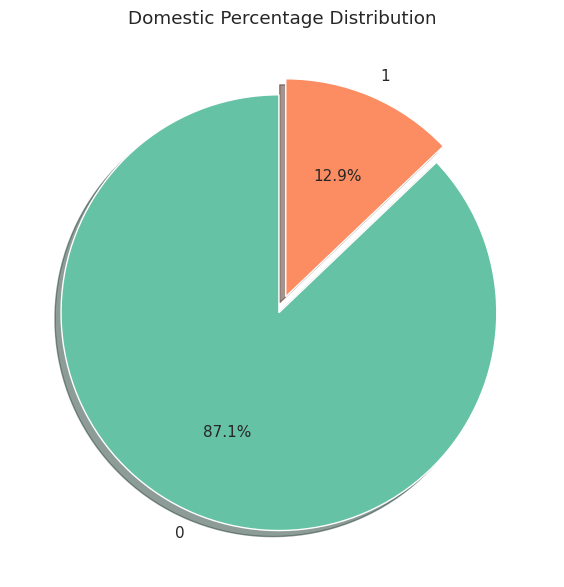

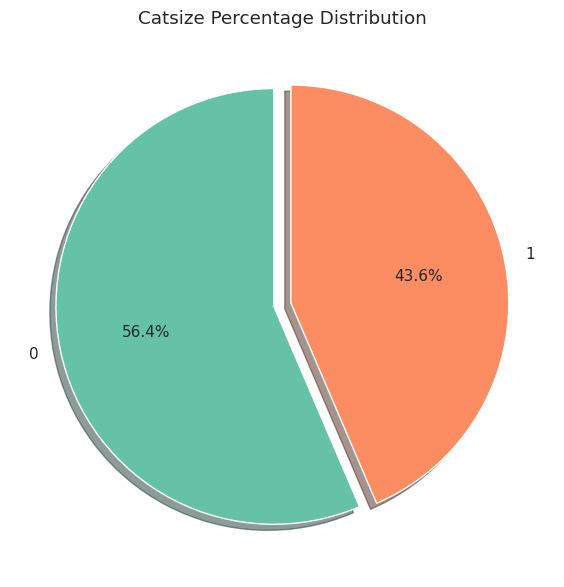

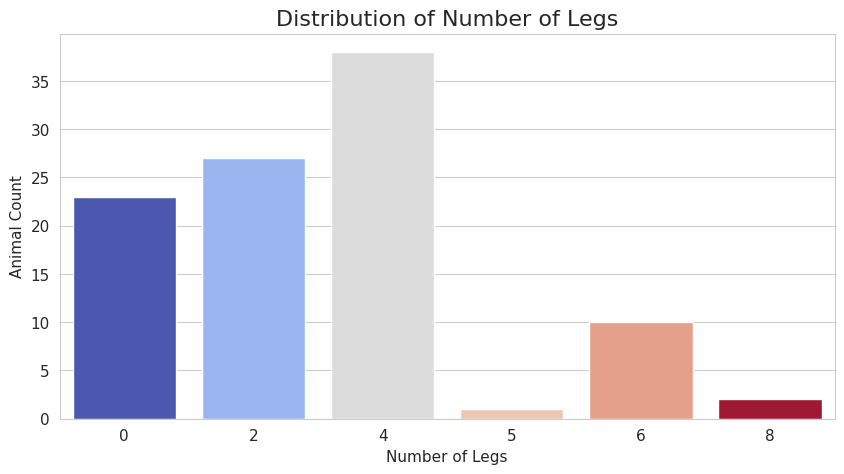

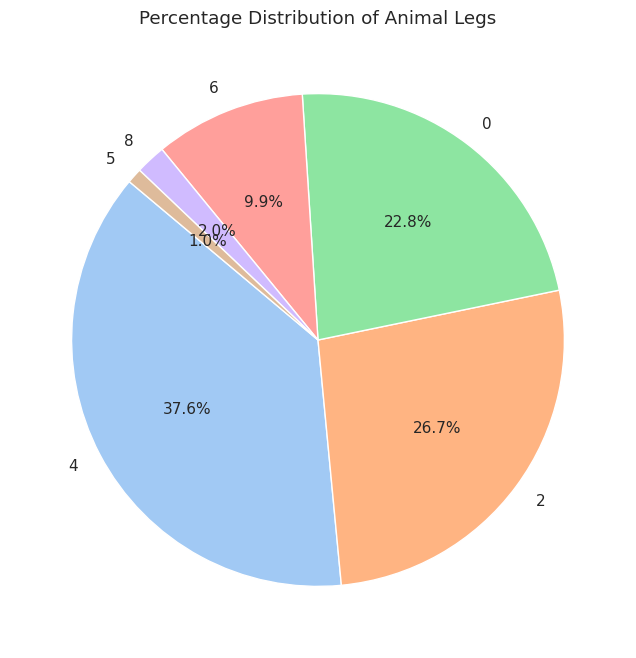

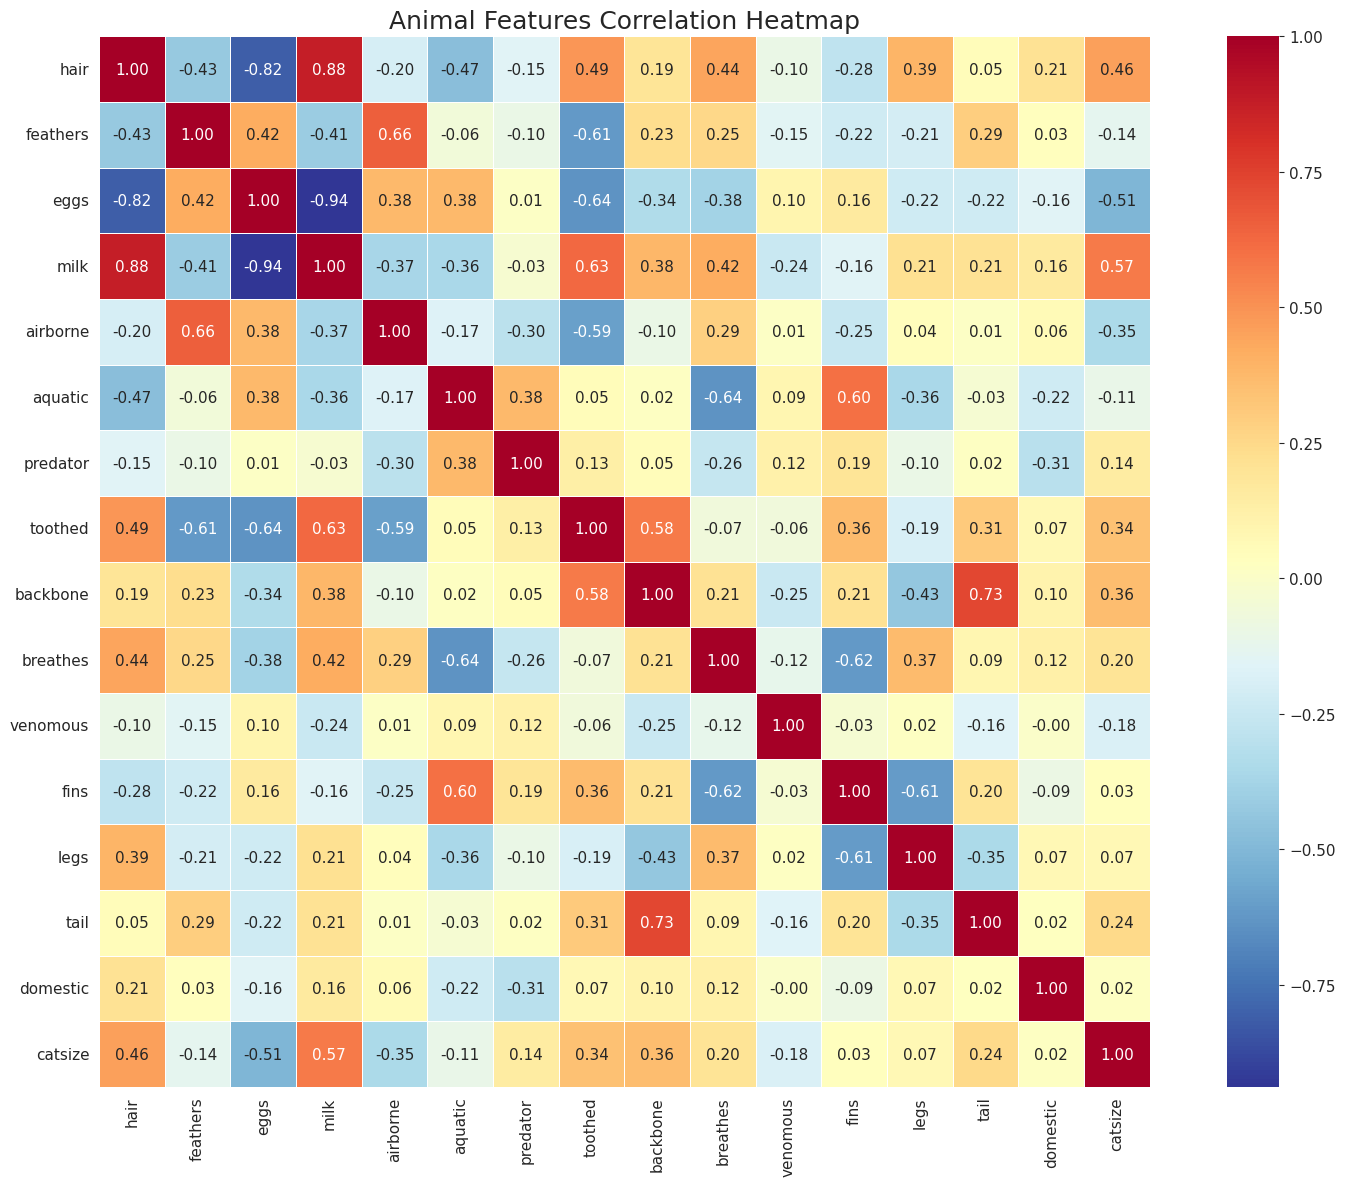

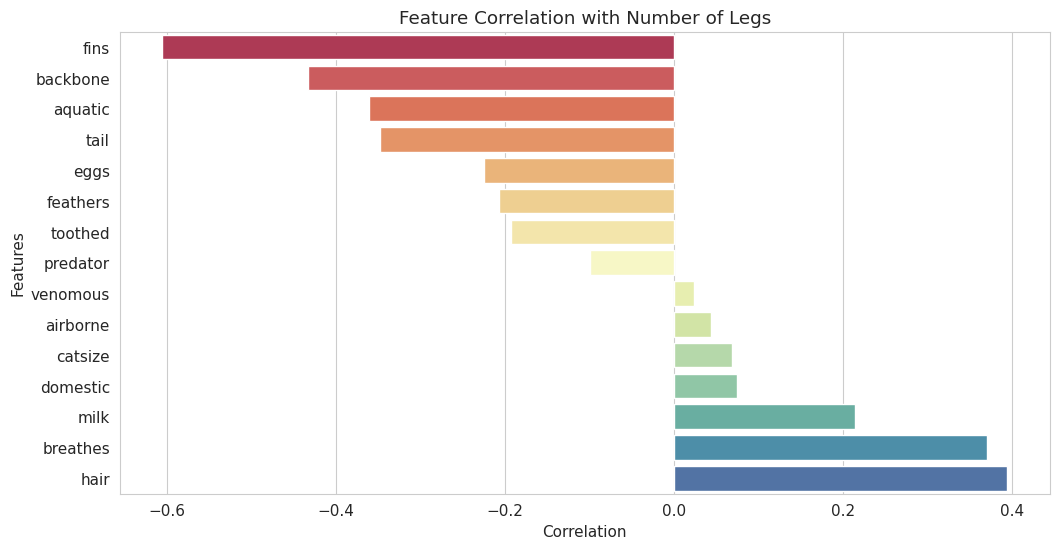

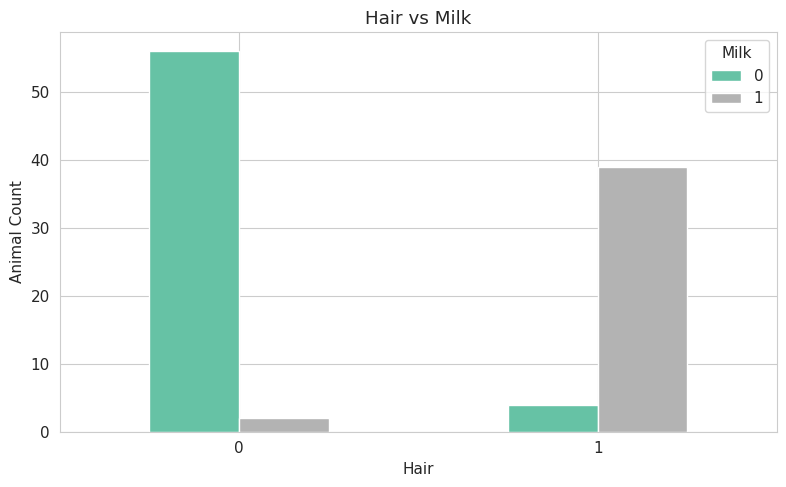

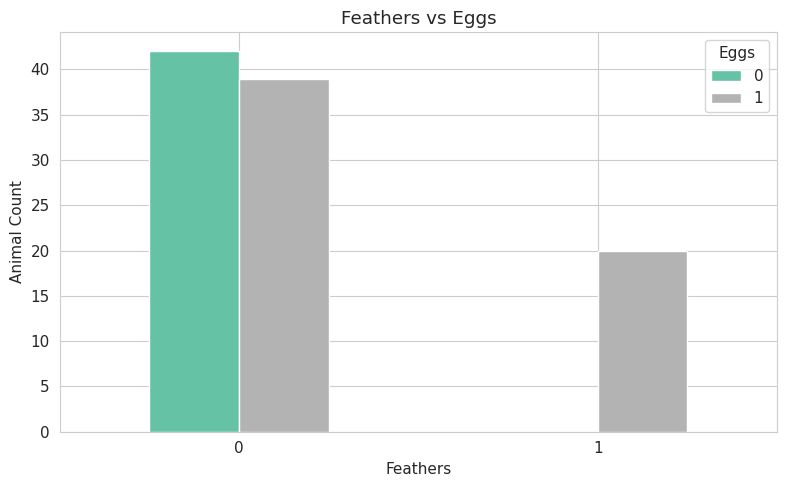

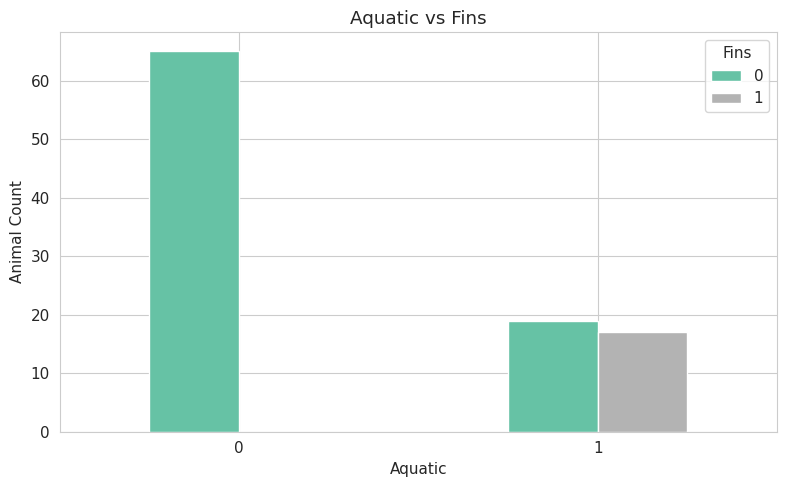

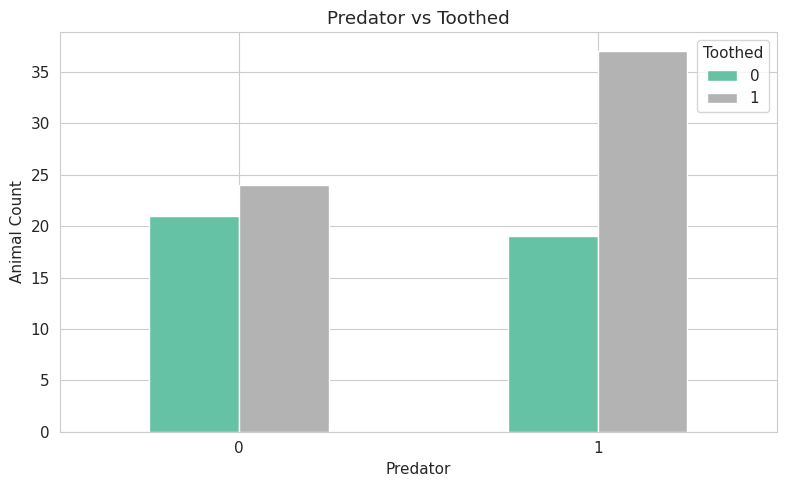

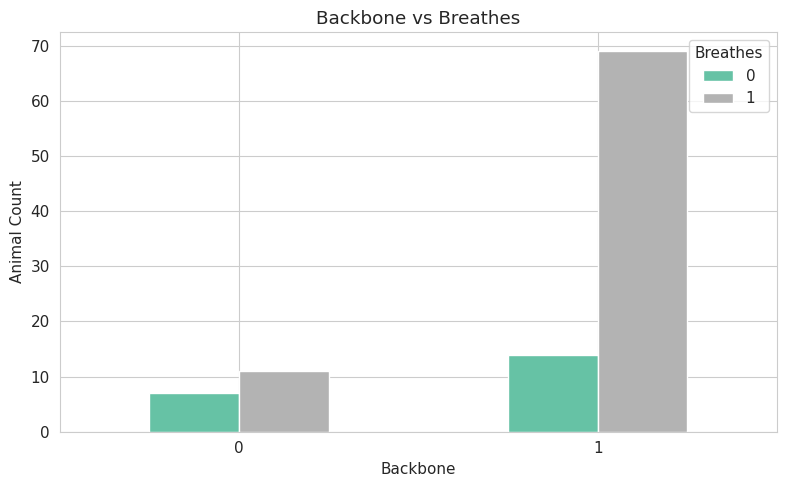

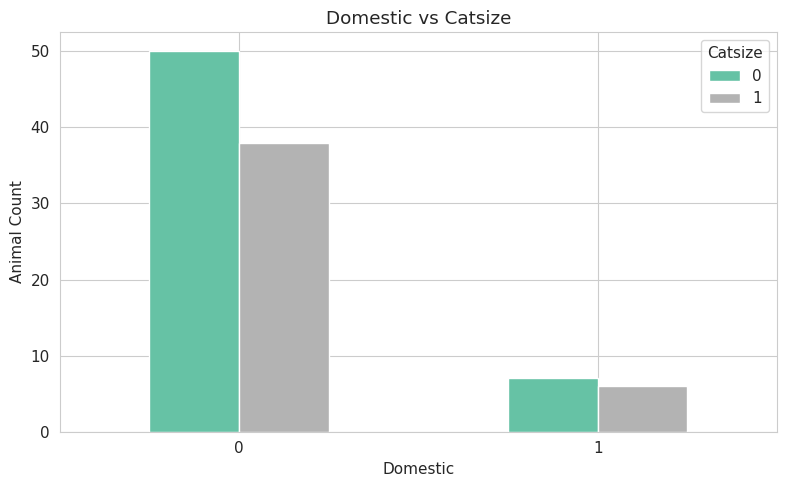

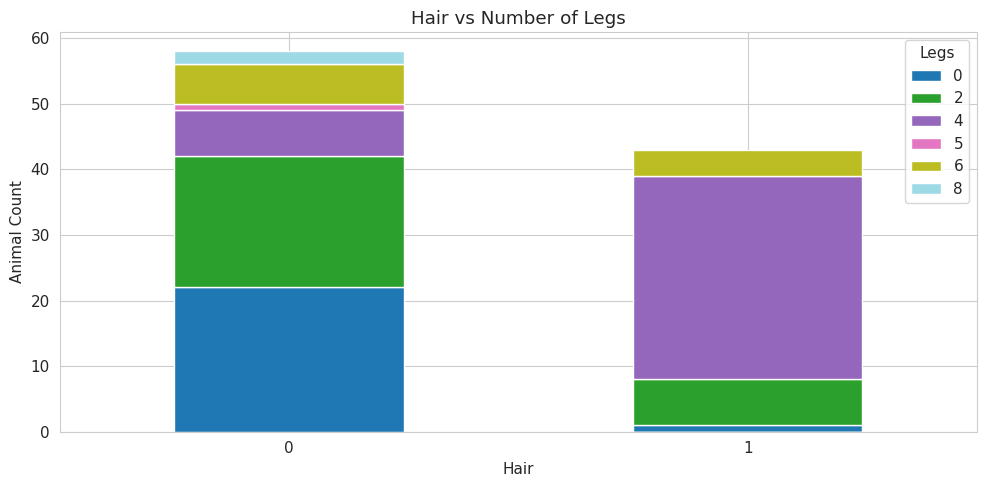

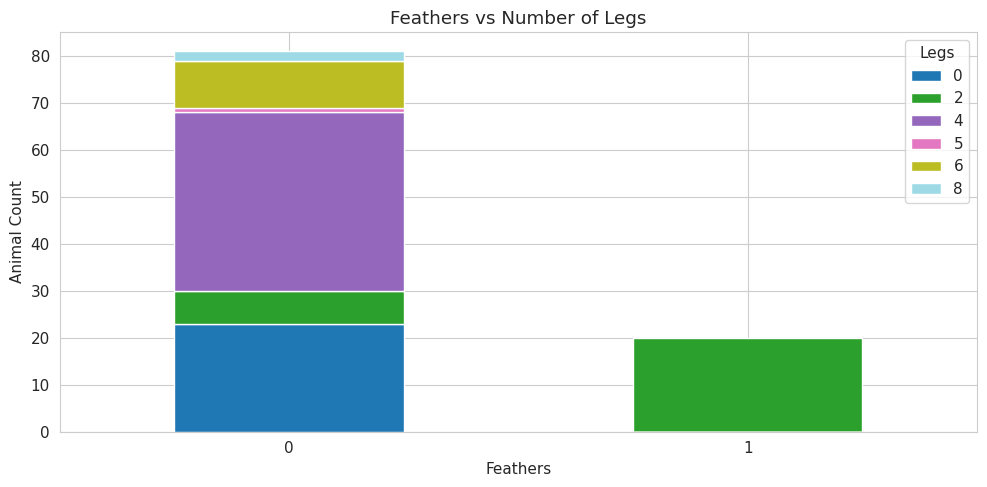

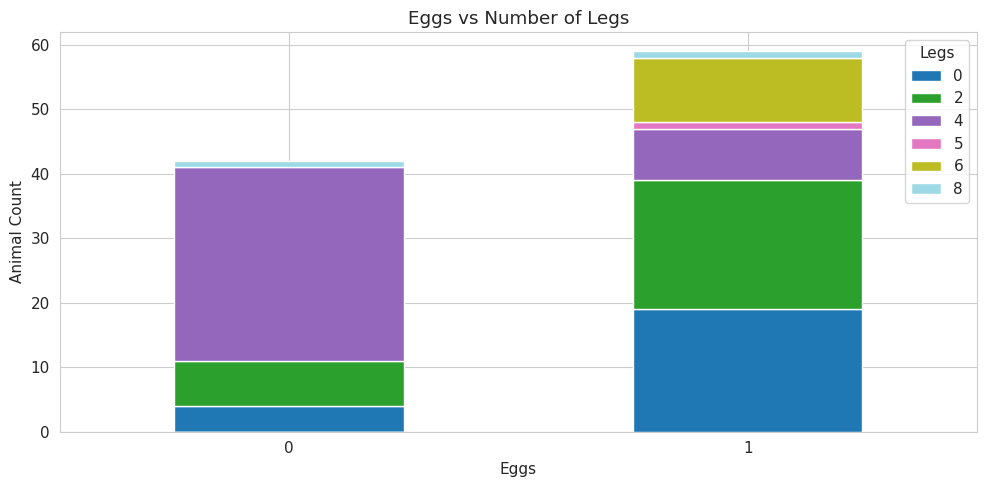

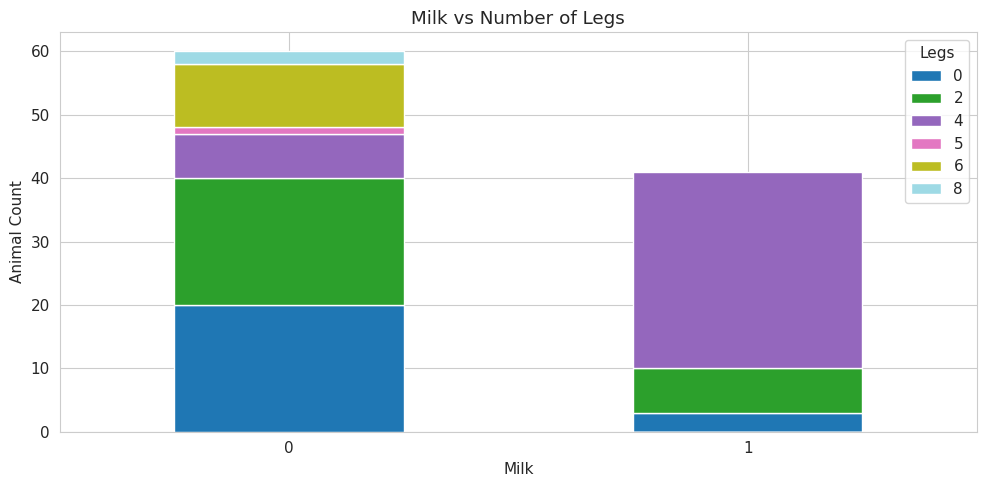

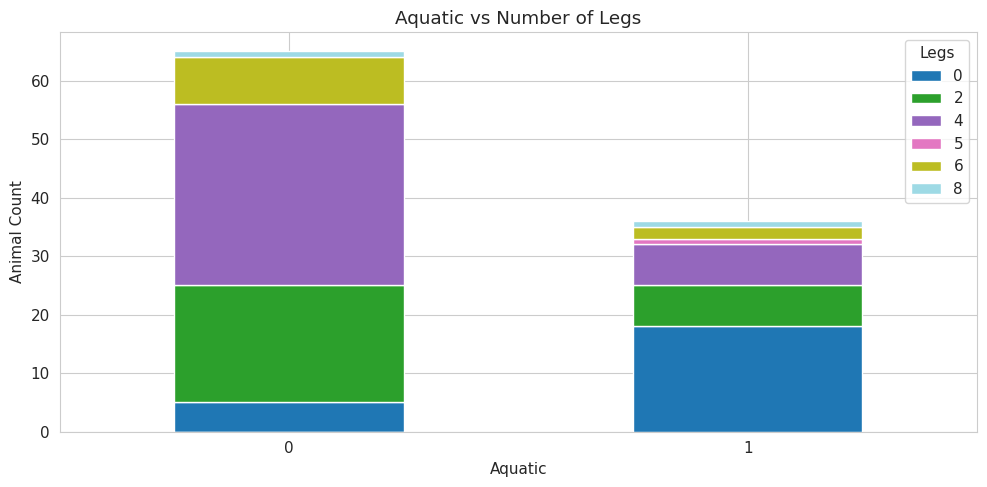

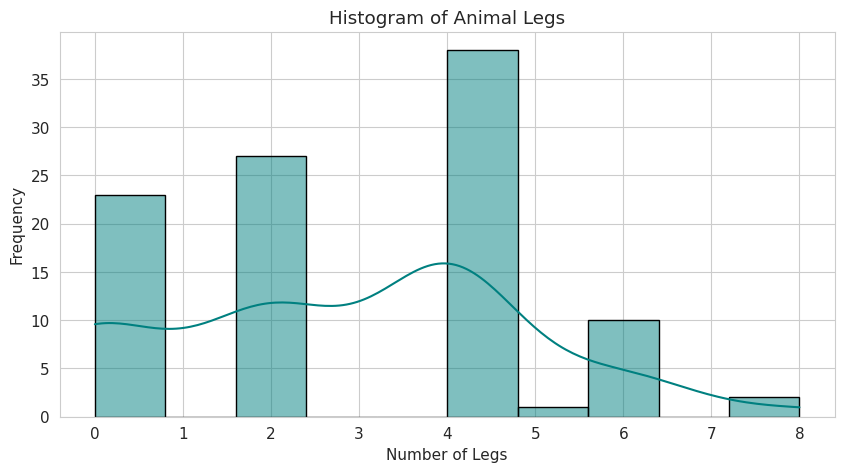

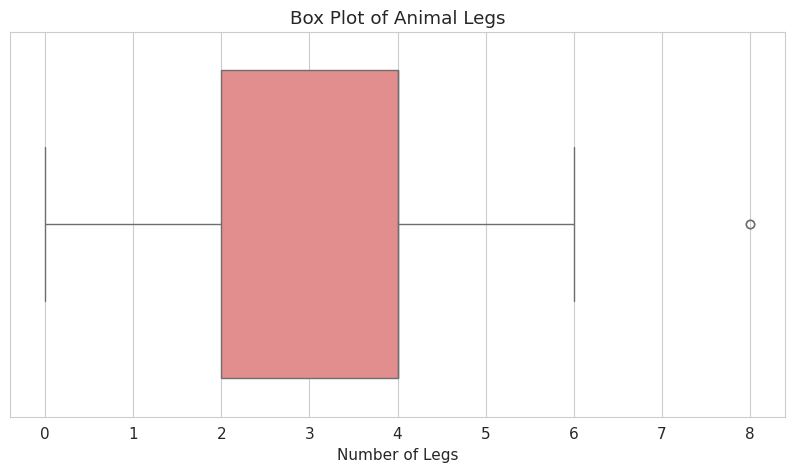

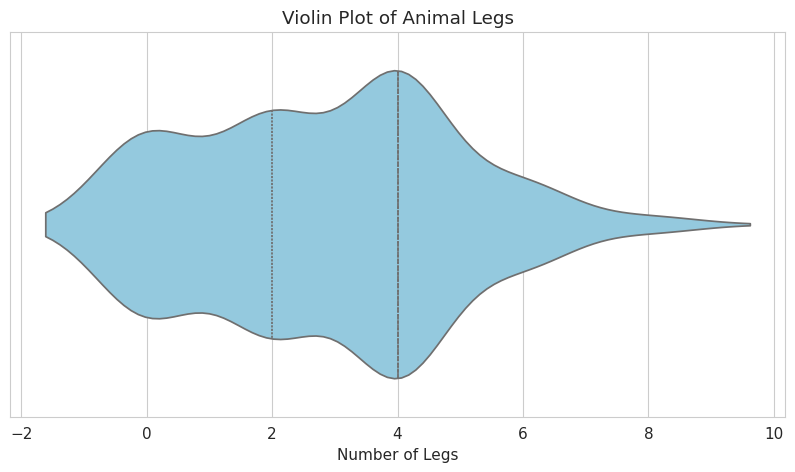

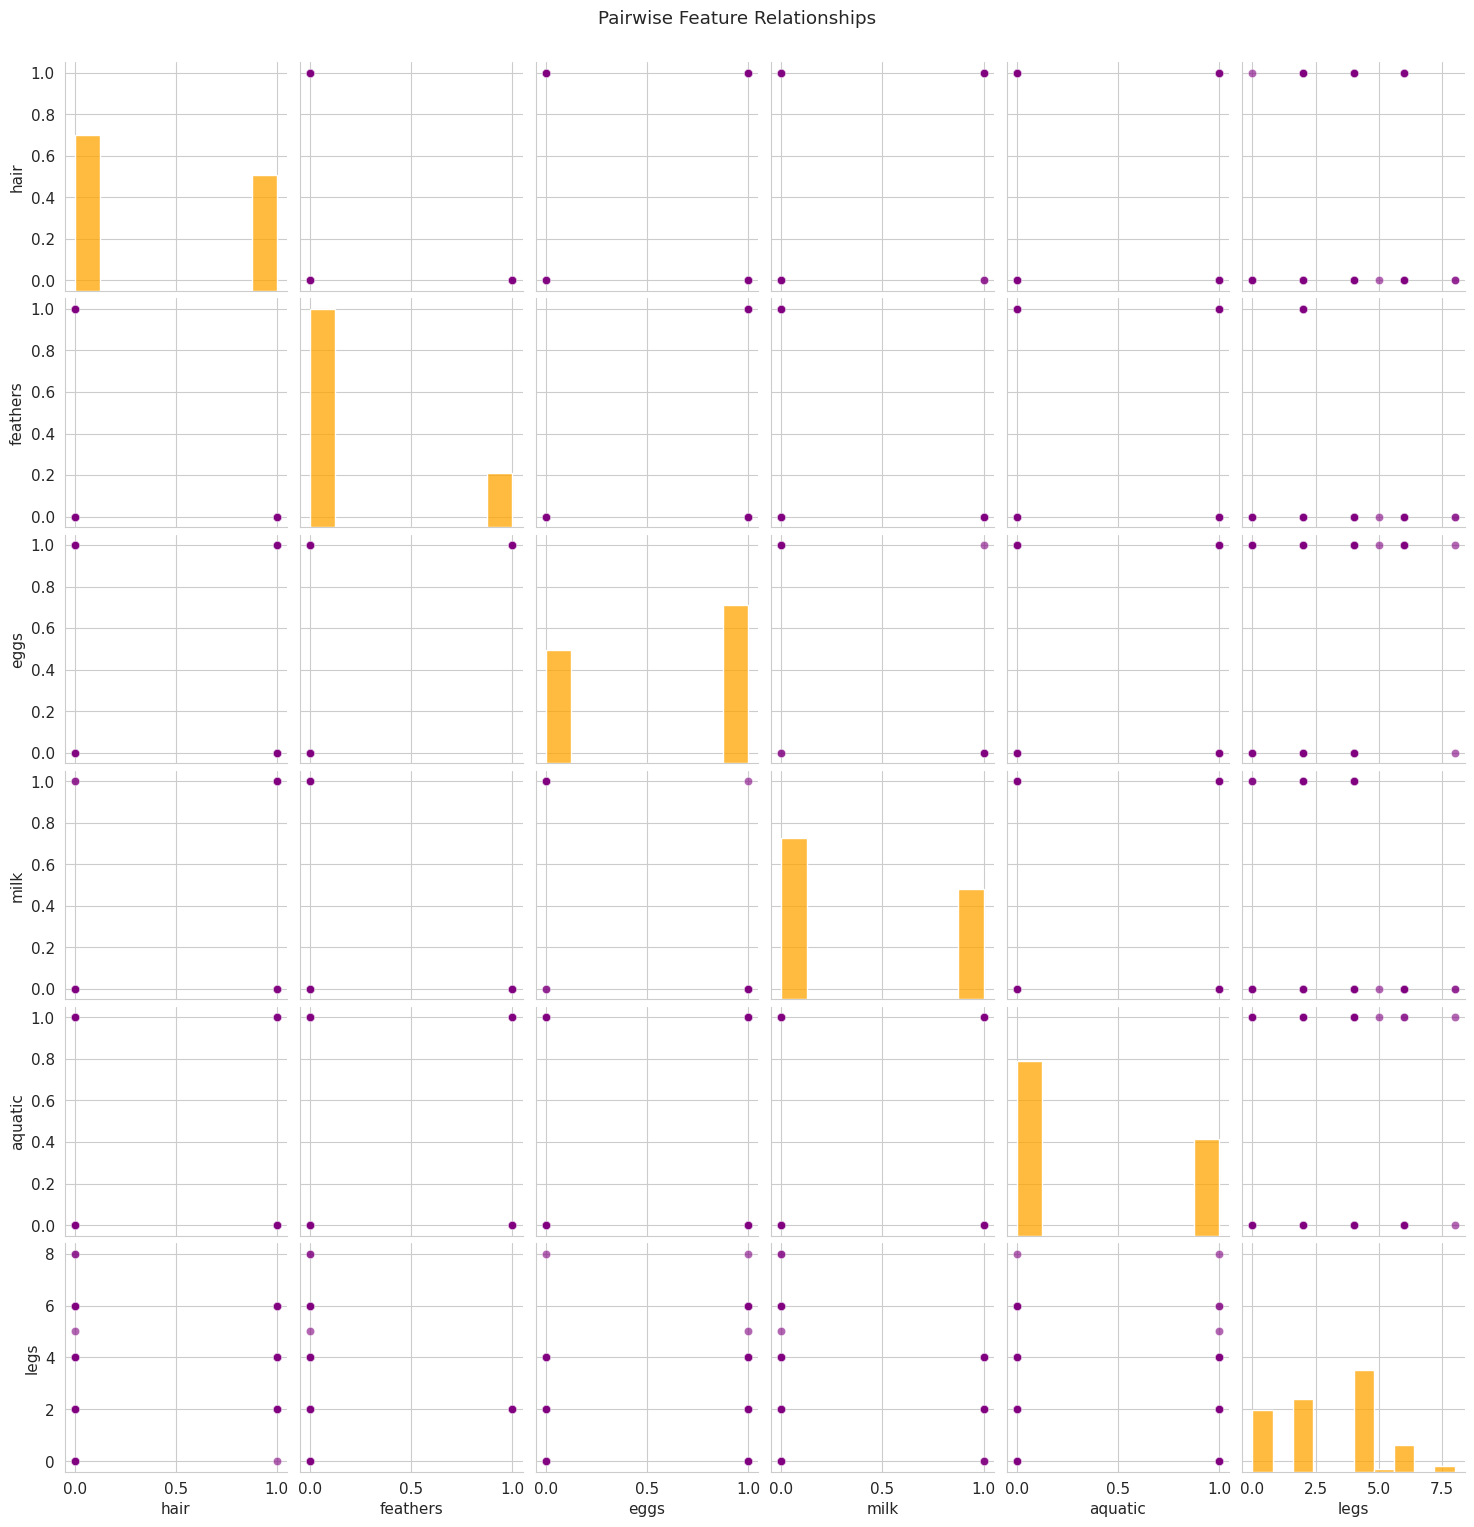

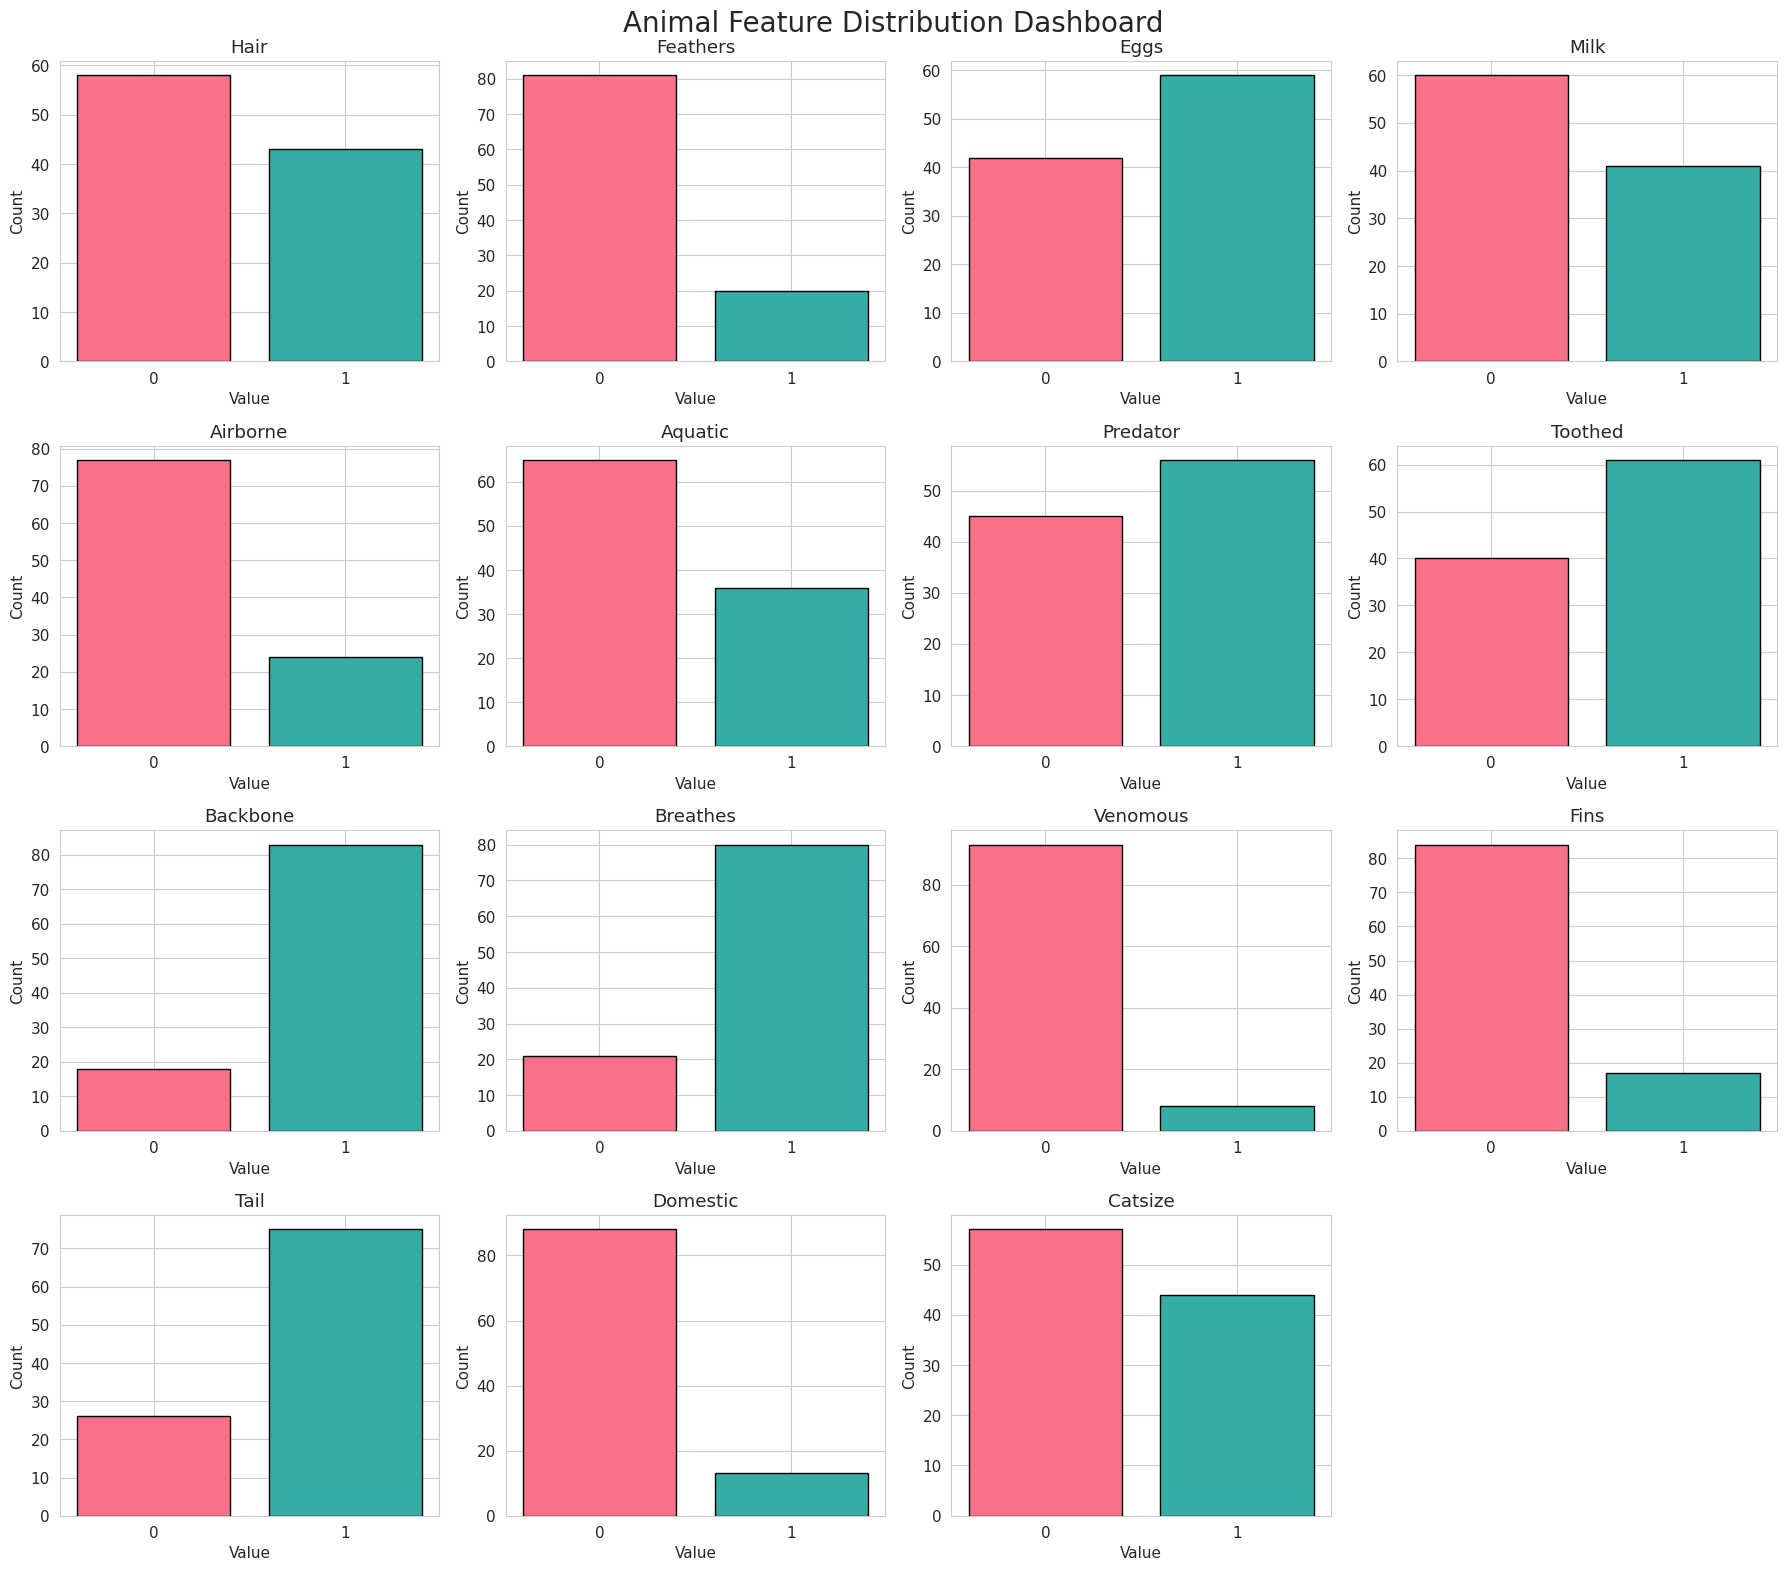

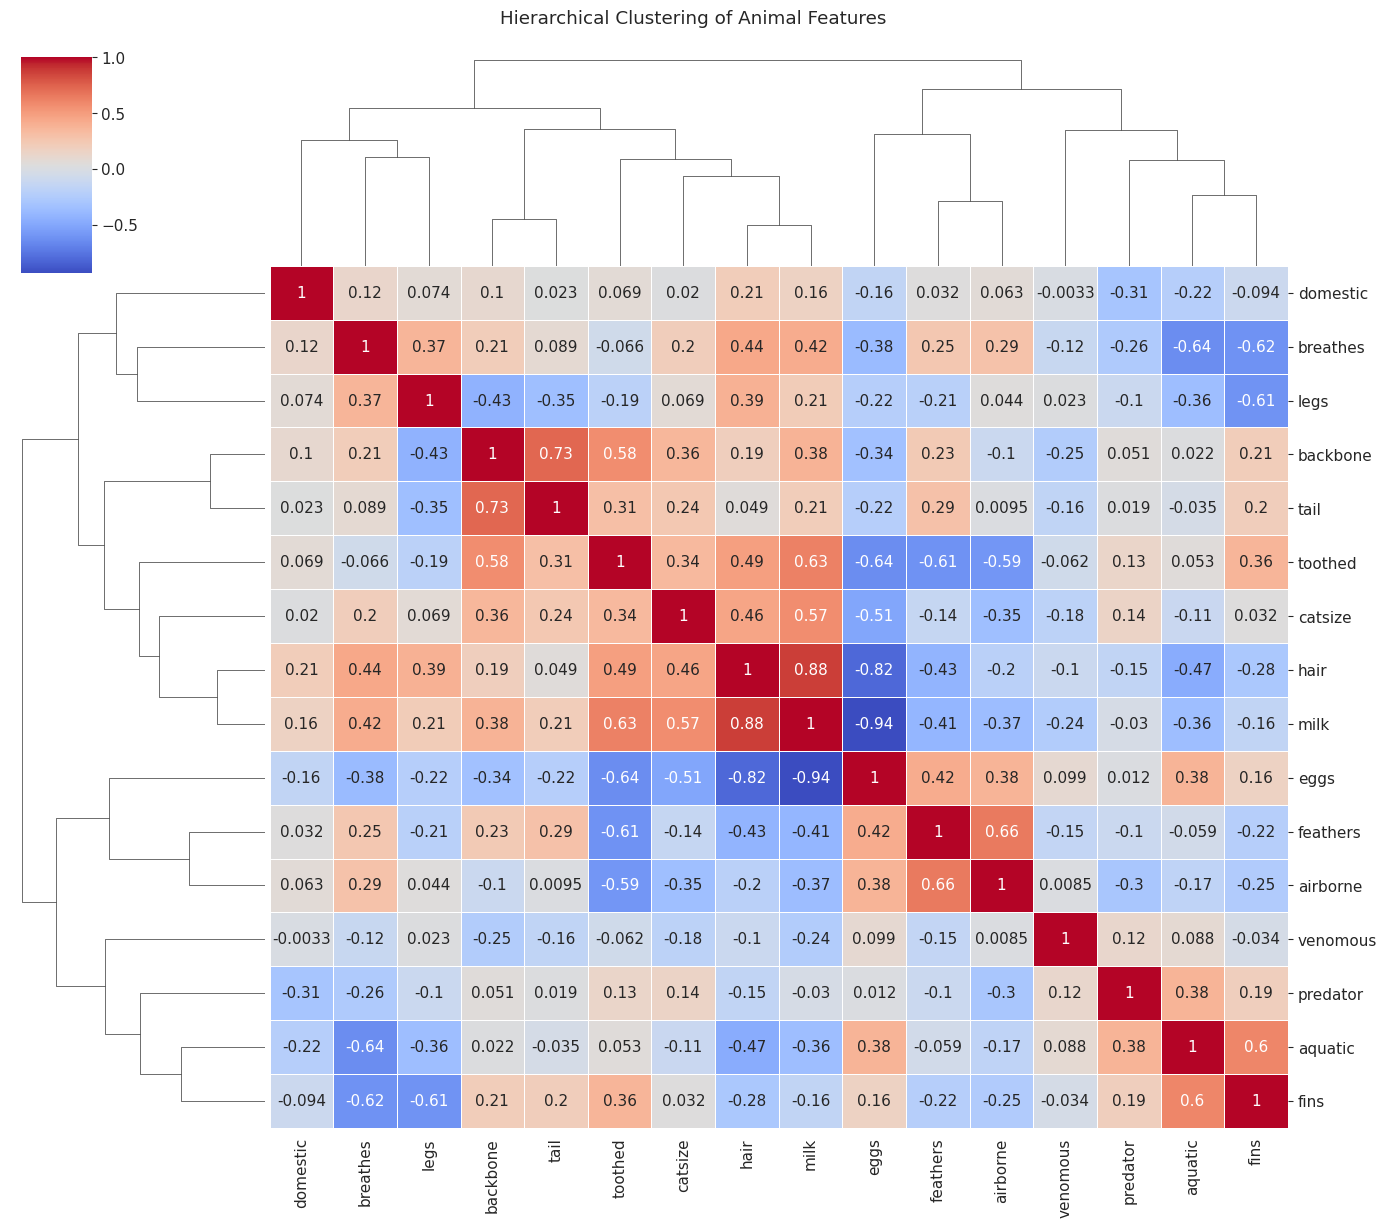


FINAL EDA SUMMARY
Total Records: 101
Total Features: 17
Missing Values: 0
Duplicate Records: 0
Unique Animal Names: 100
Unique Legs Values: [np.int64(0), np.int64(2), np.int64(4), np.int64(5), np.int64(6), np.int64(8)]

Binary Feature Summary:

HAIR
{0: 58, 1: 43}

FEATHERS
{0: 81, 1: 20}

EGGS
{1: 59, 0: 42}

MILK
{0: 60, 1: 41}

AIRBORNE
{0: 77, 1: 24}

AQUATIC
{0: 65, 1: 36}

PREDATOR
{1: 56, 0: 45}

TOOTHED
{1: 61, 0: 40}

BACKBONE
{1: 83, 0: 18}

BREATHES
{1: 80, 0: 21}

VENOMOUS
{0: 93, 1: 8}

FINS
{0: 84, 1: 17}

TAIL
{1: 75, 0: 26}

DOMESTIC
{0: 88, 1: 13}

CATSIZE
{0: 57, 1: 44}

EDA VISUALIZATION COMPLETED SUCCESSFULLY!


In [13]:
warnings.filterwarnings('ignore')

# Visualization settings
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 11

df = df.copy()

print("DATASET OVERVIEW")
print("=" * 60)

print("\nFirst 5 Rows:")
display(df.head())

print("\nLast 5 Rows:")
display(df.tail())

print("\nDataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
display(df.describe(include='all').T)

# ============================================================
# 3. DATA CLEANING ANALYSIS
# ============================================================

print("\nMissing Values:")
print(df.isnull().sum())

print("\nTotal Missing Values:", df.isnull().sum().sum())

print("\nDuplicate Records:", df.duplicated().sum())

print("\nUnique Values:")
print(df.nunique())

# Missing values visualization
plt.figure(figsize=(14, 5))
sns.heatmap(df.isnull(), cmap='magma', cbar=False, yticklabels=False)
plt.title("Missing Values Heatmap", fontsize=16)
plt.xlabel("Features")
plt.show()

# ============================================================
# 4. ANIMAL NAME DISTRIBUTION
# ============================================================

plt.figure(figsize=(14, 6))
animal_counts = df['animal_name'].value_counts()

sns.barplot(
    x=animal_counts.index,
    y=animal_counts.values,
    hue=animal_counts.index,
    palette='viridis',
    legend=False
)

plt.title("Animal Name Distribution", fontsize=16)
plt.xlabel("Animal Name")
plt.ylabel("Count")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

# ============================================================
# 5. INDIVIDUAL FEATURE COUNT PLOTS
# ============================================================

binary_features = [
    'hair', 'feathers', 'eggs', 'milk', 'airborne',
    'aquatic', 'predator', 'toothed', 'backbone',
    'breathes', 'venomous', 'fins', 'tail',
    'domestic', 'catsize'
]

colors = sns.color_palette("husl", len(binary_features))

for i, col in enumerate(binary_features):

    plt.figure(figsize=(7, 4))

    sns.countplot(
        data=df,
        x=col,
        hue=col,
        palette=[colors[i], '#FF8C42'],
        legend=False
    )

    plt.title(f"Distribution of {col.capitalize()}", fontsize=14)
    plt.xlabel(col.capitalize())
    plt.ylabel("Number of Animals")

    plt.tight_layout()
    plt.show()

# ============================================================
# 6. PIE CHARTS FOR BINARY FEATURES
# ============================================================

for col in binary_features:

    counts = df[col].value_counts().sort_index()

    plt.figure(figsize=(6, 6))

    plt.pie(
        counts.values,
        labels=counts.index,
        autopct='%1.1f%%',
        startangle=90,
        colors=sns.color_palette("Set2", len(counts)),
        explode=[0.04] * len(counts),
        shadow=True
    )

    plt.title(f"{col.capitalize()} Percentage Distribution")
    plt.tight_layout()
    plt.show()

# ============================================================
# 7. LEGS DISTRIBUTION
# ============================================================

plt.figure(figsize=(10, 5))

sns.countplot(
    data=df,
    x='legs',
    hue='legs',
    palette='coolwarm',
    legend=False
)

plt.title("Distribution of Number of Legs", fontsize=16)
plt.xlabel("Number of Legs")
plt.ylabel("Animal Count")
plt.show()

# Legs pie chart
plt.figure(figsize=(8, 8))

leg_counts = df['legs'].value_counts()

plt.pie(
    leg_counts.values,
    labels=leg_counts.index,
    autopct='%1.1f%%',
    colors=sns.color_palette("pastel"),
    startangle=140
)

plt.title("Percentage Distribution of Animal Legs")
plt.show()

# ============================================================
# 8. CORRELATION HEATMAP
# ============================================================

numeric_df = df.select_dtypes(include=np.number)

plt.figure(figsize=(16, 12))

correlation = numeric_df.corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap='RdYlBu_r',
    linewidths=0.5,
    fmt='.2f',
    square=True
)

plt.title("Animal Features Correlation Heatmap", fontsize=18)
plt.tight_layout()
plt.show()

# ============================================================
# 9. CORRELATION WITH LEGS
# ============================================================

if 'legs' in numeric_df.columns:

    plt.figure(figsize=(12, 6))

    leg_corr = numeric_df.corr()['legs'].drop('legs').sort_values()

    sns.barplot(
        x=leg_corr.values,
        y=leg_corr.index,
        hue=leg_corr.index,
        palette='Spectral',
        legend=False
    )

    plt.title("Feature Correlation with Number of Legs")
    plt.xlabel("Correlation")
    plt.ylabel("Features")
    plt.show()

# ============================================================
# 10. FEATURE COMPARISON BAR CHARTS
# ============================================================

comparison_pairs = [
    ('hair', 'milk'),
    ('feathers', 'eggs'),
    ('aquatic', 'fins'),
    ('predator', 'toothed'),
    ('backbone', 'breathes'),
    ('domestic', 'catsize')
]

for col1, col2 in comparison_pairs:

    comparison = pd.crosstab(df[col1], df[col2])

    comparison.plot(
        kind='bar',
        figsize=(8, 5),
        colormap='Set2'
    )

    plt.title(f"{col1.capitalize()} vs {col2.capitalize()}")
    plt.xlabel(col1.capitalize())
    plt.ylabel("Animal Count")
    plt.legend(title=col2.capitalize())
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()

# ============================================================
# 11. STACKED BAR CHART
# ============================================================

for col in ['hair', 'feathers', 'eggs', 'milk', 'aquatic']:

    if col in df.columns:

        counts = pd.crosstab(df[col], df['legs'])

        counts.plot(
            kind='bar',
            stacked=True,
            figsize=(10, 5),
            colormap='tab20'
        )

        plt.title(f"{col.capitalize()} vs Number of Legs")
        plt.xlabel(col.capitalize())
        plt.ylabel("Animal Count")
        plt.legend(title="Legs")
        plt.xticks(rotation=0)
        plt.tight_layout()
        plt.show()

# ============================================================
# 12. HISTOGRAM AND KDE FOR LEGS
# ============================================================

plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x='legs',
    bins=10,
    kde=True,
    color='teal',
    edgecolor='black'
)

plt.title("Histogram of Animal Legs")
plt.xlabel("Number of Legs")
plt.ylabel("Frequency")
plt.show()

# ============================================================
# 13. BOX PLOT
# ============================================================

plt.figure(figsize=(10, 5))

sns.boxplot(
    data=df,
    x='legs',
    color='lightcoral'
)

plt.title("Box Plot of Animal Legs")
plt.xlabel("Number of Legs")
plt.show()

# ============================================================
# 14. VIOLIN PLOT
# ============================================================

plt.figure(figsize=(10, 5))

sns.violinplot(
    data=df,
    x='legs',
    color='skyblue',
    inner='quartile'
)

plt.title("Violin Plot of Animal Legs")
plt.xlabel("Number of Legs")
plt.show()

# ============================================================
# 15. PAIRPLOT
# ============================================================

pair_features = [
    'hair', 'feathers', 'eggs',
    'milk', 'aquatic', 'legs'
]

sns.pairplot(
    df[pair_features].dropna(),
    diag_kind='hist',
    plot_kws={'alpha': 0.6, 'color': 'purple'},
    diag_kws={'color': 'orange'}
)

plt.suptitle("Pairwise Feature Relationships", y=1.02)
plt.show()

# ============================================================
# 16. FEATURE DISTRIBUTION SUBPLOTS
# ============================================================

fig, axes = plt.subplots(4, 4, figsize=(18, 16))

for i, col in enumerate(binary_features):

    ax = axes[i // 4, i % 4]

    counts = df[col].value_counts().sort_index()

    ax.bar(
        counts.index.astype(str),
        counts.values,
        color=sns.color_palette("husl", len(counts)),
        edgecolor='black'
    )

    ax.set_title(col.capitalize())
    ax.set_xlabel("Value")
    ax.set_ylabel("Count")

# Hide unused subplot
for j in range(len(binary_features), 16):
    axes[j // 4, j % 4].axis('off')

plt.suptitle("Animal Feature Distribution Dashboard", fontsize=20)
plt.tight_layout()
plt.show()

# ============================================================
# 17. CORRELATION CLUSTER MAP
# ============================================================

sns.clustermap(
    numeric_df.corr(),
    cmap='coolwarm',
    annot=True,
    figsize=(14, 12),
    linewidths=0.5
)

plt.suptitle("Hierarchical Clustering of Animal Features", y=1.02)
plt.show()

# ============================================================
# 18. FINAL EDA SUMMARY
# ============================================================

print("\n" + "=" * 60)
print("FINAL EDA SUMMARY")
print("=" * 60)

print("Total Records:", df.shape[0])
print("Total Features:", df.shape[1])
print("Missing Values:", df.isnull().sum().sum())
print("Duplicate Records:", df.duplicated().sum())
print("Unique Animal Names:", df['animal_name'].nunique())
print("Unique Legs Values:", sorted(df['legs'].dropna().unique()))

print("\nBinary Feature Summary:")

for col in binary_features:
    print(f"\n{col.upper()}")
    print(df[col].value_counts().to_dict())

print("\nEDA VISUALIZATION COMPLETED SUCCESSFULLY!")


## Feature engineering

ANIMAL CLASSIFICATION DATASET
Dataset Shape: (101, 17)


,animal_name,hair,feathers,eggs,milk,airborne,aquatic,predator,toothed,backbone,breathes,venomous,fins,legs,tail,domestic,catsize
0,aardvark,1,0,0,1,0,0,1,1,1,1,0,0,4,0,0,1
1,antelope,1,0,0,1,0,0,0,1,1,1,0,0,4,1,0,1
2,bass,0,0,1,0,0,1,1,1,1,0,0,1,0,1,0,0
3,bear,1,0,0,1,0,0,1,1,1,1,0,0,4,0,0,1
4,boar,1,0,0,1,0,0,1,1,1,1,0,0,4,1,0,1



Animal Class Distribution:
class_name
Mammal          41
Bird            20
Fish            13
Invertebrate    10
Insect           8
Reptile          5
Amphibian        4
Name: count, dtype: int64

Input Shape: (101, 16)
Target Shape: (101,)

Input Features:
['hair', 'feathers', 'eggs', 'milk', 'airborne', 'aquatic', 'predator', 'toothed', 'backbone', 'breathes', 'venomous', 'fins', 'legs', 'tail', 'domestic', 'catsize']

Target Classes:
class_type
1    41
2    20
3     5
4    13
5     4
6     8
7    10
Name: count, dtype: int64

Encoded Target Labels:
Mammal = 0
Bird = 1
Reptile = 2
Fish = 3
Amphibian = 4
Insect = 5
Invertebrate = 6

Training Shape: (80, 16)
Testing Shape: (21, 16)

Numerical Features: ['hair', 'feathers', 'eggs', 'milk', 'airborne', 'aquatic', 'predator', 'toothed', 'backbone', 'breathes', 'venomous', 'fins', 'legs', 'tail', 'domestic', 'catsize']
Categorical Features: []

MODEL: Logistic Regression
Accuracy  : 100.00%
Precision : 100.00%
Recall    : 100.00%
F1 Scor

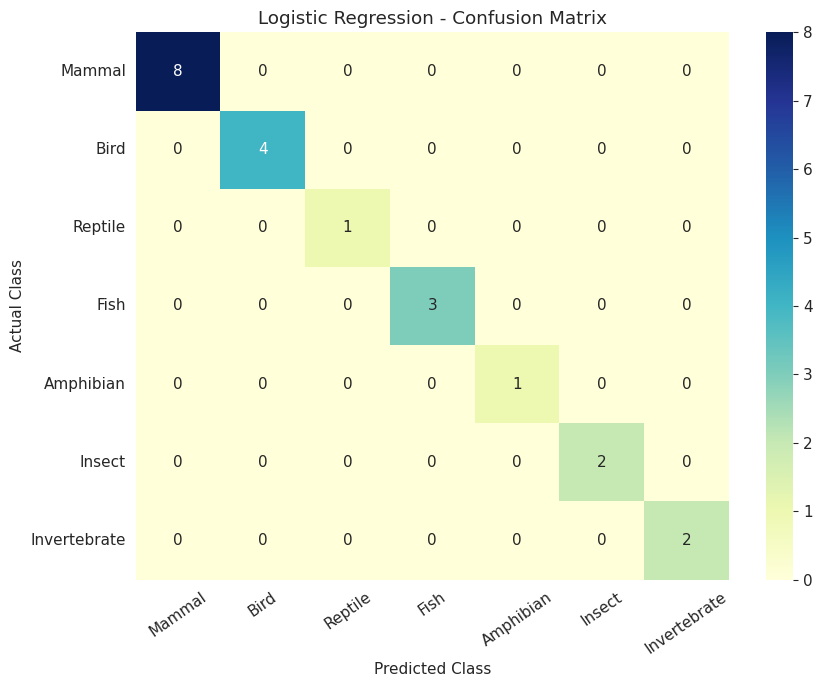


MODEL: Decision Tree
Accuracy  : 100.00%
Precision : 100.00%
Recall    : 100.00%
F1 Score  : 100.00%
ROC AUC   : 100.00%

Classification Report:
              precision    recall  f1-score   support

      Mammal       1.00      1.00      1.00         8
        Bird       1.00      1.00      1.00         4
     Reptile       1.00      1.00      1.00         1
        Fish       1.00      1.00      1.00         3
   Amphibian       1.00      1.00      1.00         1
      Insect       1.00      1.00      1.00         2
Invertebrate       1.00      1.00      1.00         2

    accuracy                           1.00        21
   macro avg       1.00      1.00      1.00        21
weighted avg       1.00      1.00      1.00        21



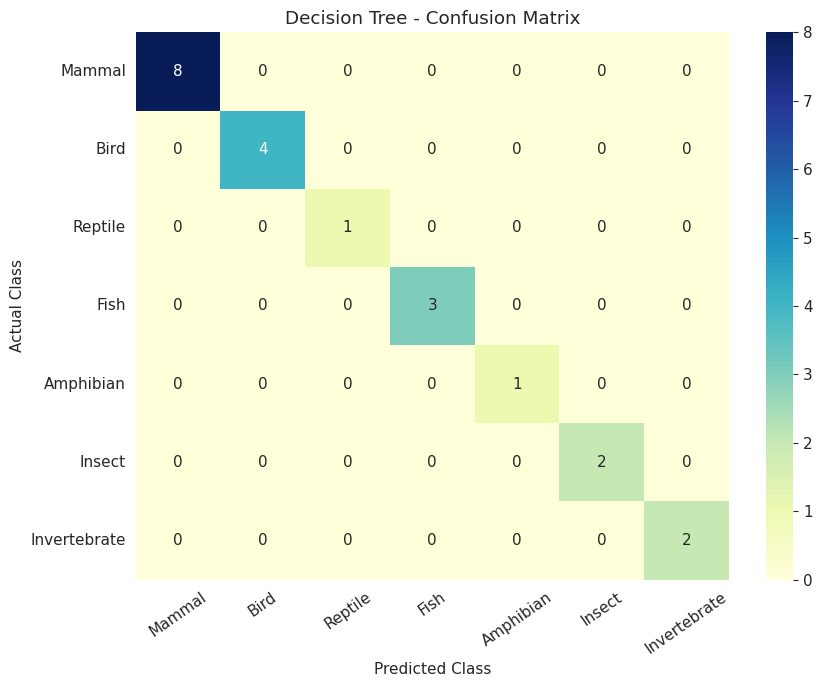


MODEL: Random Forest
Accuracy  : 100.00%
Precision : 100.00%
Recall    : 100.00%
F1 Score  : 100.00%
ROC AUC   : 100.00%

Classification Report:
              precision    recall  f1-score   support

      Mammal       1.00      1.00      1.00         8
        Bird       1.00      1.00      1.00         4
     Reptile       1.00      1.00      1.00         1
        Fish       1.00      1.00      1.00         3
   Amphibian       1.00      1.00      1.00         1
      Insect       1.00      1.00      1.00         2
Invertebrate       1.00      1.00      1.00         2

    accuracy                           1.00        21
   macro avg       1.00      1.00      1.00        21
weighted avg       1.00      1.00      1.00        21



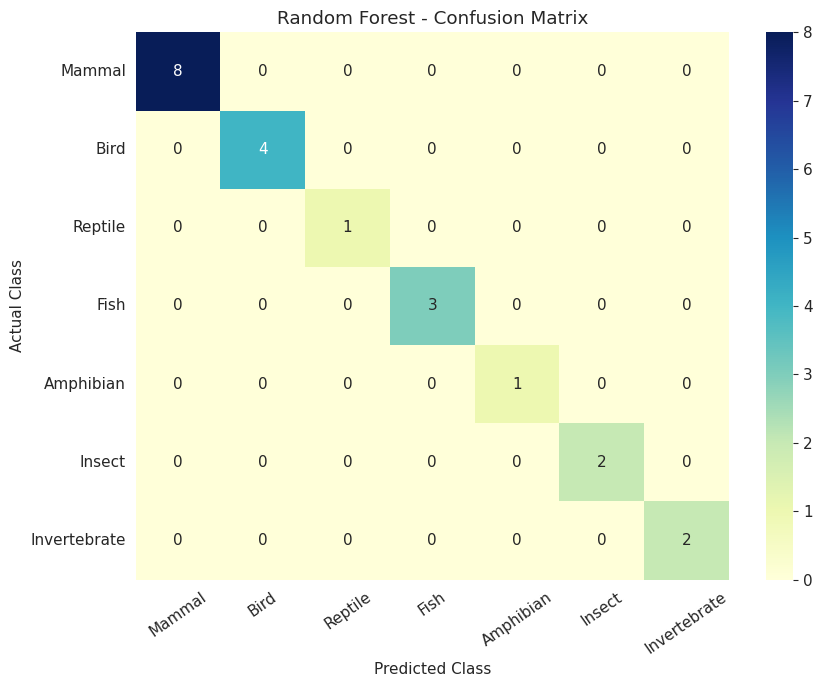


MODEL: Gradient Boosting
Accuracy  : 100.00%
Precision : 100.00%
Recall    : 100.00%
F1 Score  : 100.00%
ROC AUC   : 100.00%

Classification Report:
              precision    recall  f1-score   support

      Mammal       1.00      1.00      1.00         8
        Bird       1.00      1.00      1.00         4
     Reptile       1.00      1.00      1.00         1
        Fish       1.00      1.00      1.00         3
   Amphibian       1.00      1.00      1.00         1
      Insect       1.00      1.00      1.00         2
Invertebrate       1.00      1.00      1.00         2

    accuracy                           1.00        21
   macro avg       1.00      1.00      1.00        21
weighted avg       1.00      1.00      1.00        21



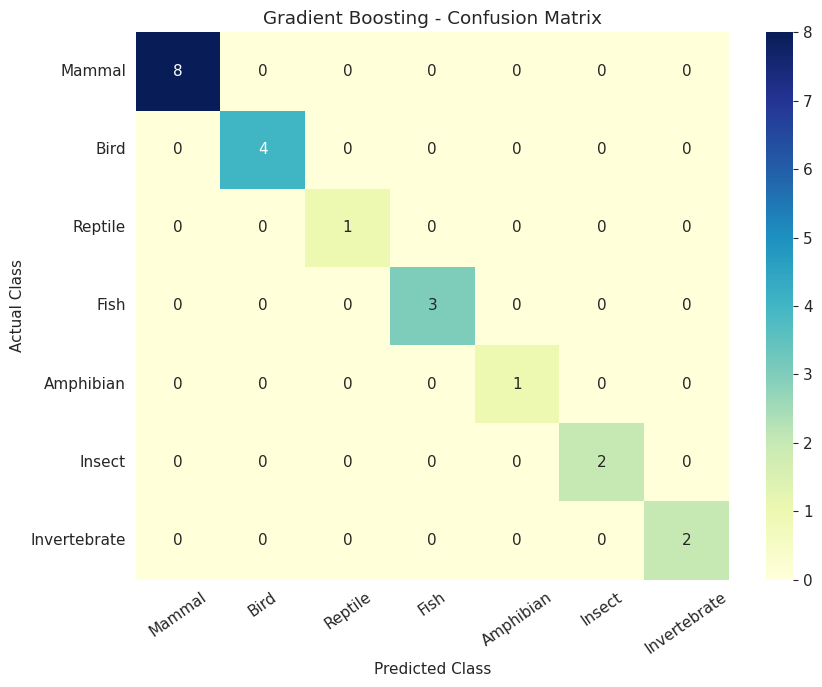


MODEL: Extra Trees
Accuracy  : 100.00%
Precision : 100.00%
Recall    : 100.00%
F1 Score  : 100.00%
ROC AUC   : 100.00%

Classification Report:
              precision    recall  f1-score   support

      Mammal       1.00      1.00      1.00         8
        Bird       1.00      1.00      1.00         4
     Reptile       1.00      1.00      1.00         1
        Fish       1.00      1.00      1.00         3
   Amphibian       1.00      1.00      1.00         1
      Insect       1.00      1.00      1.00         2
Invertebrate       1.00      1.00      1.00         2

    accuracy                           1.00        21
   macro avg       1.00      1.00      1.00        21
weighted avg       1.00      1.00      1.00        21



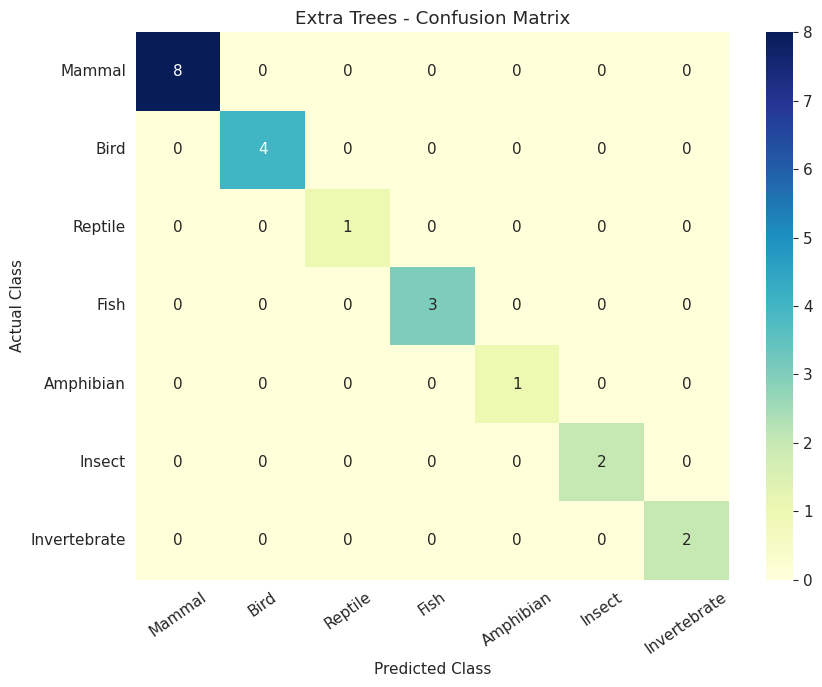


MODEL: AdaBoost
Accuracy  : 85.71%
Precision : 78.57%
Recall    : 85.71%
F1 Score  : 80.95%
ROC AUC   : 98.53%

Classification Report:
              precision    recall  f1-score   support

      Mammal       1.00      1.00      1.00         8
        Bird       1.00      1.00      1.00         4
     Reptile       0.00      0.00      0.00         1
        Fish       1.00      1.00      1.00         3
   Amphibian       0.50      1.00      0.67         1
      Insect       0.00      0.00      0.00         2
Invertebrate       0.50      1.00      0.67         2

    accuracy                           0.86        21
   macro avg       0.57      0.71      0.62        21
weighted avg       0.79      0.86      0.81        21



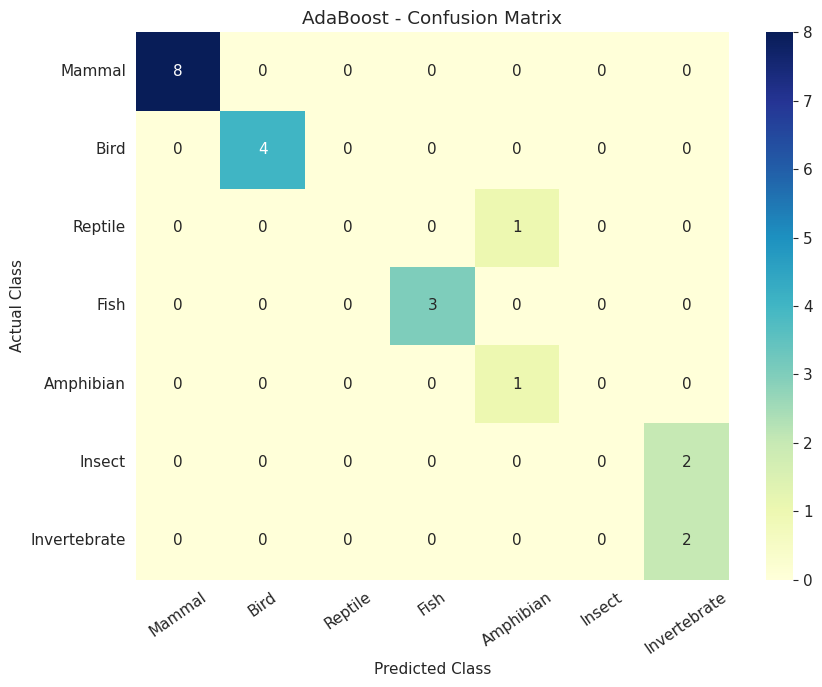


MODEL: KNN
Accuracy  : 100.00%
Precision : 100.00%
Recall    : 100.00%
F1 Score  : 100.00%
ROC AUC   : 100.00%

Classification Report:
              precision    recall  f1-score   support

      Mammal       1.00      1.00      1.00         8
        Bird       1.00      1.00      1.00         4
     Reptile       1.00      1.00      1.00         1
        Fish       1.00      1.00      1.00         3
   Amphibian       1.00      1.00      1.00         1
      Insect       1.00      1.00      1.00         2
Invertebrate       1.00      1.00      1.00         2

    accuracy                           1.00        21
   macro avg       1.00      1.00      1.00        21
weighted avg       1.00      1.00      1.00        21



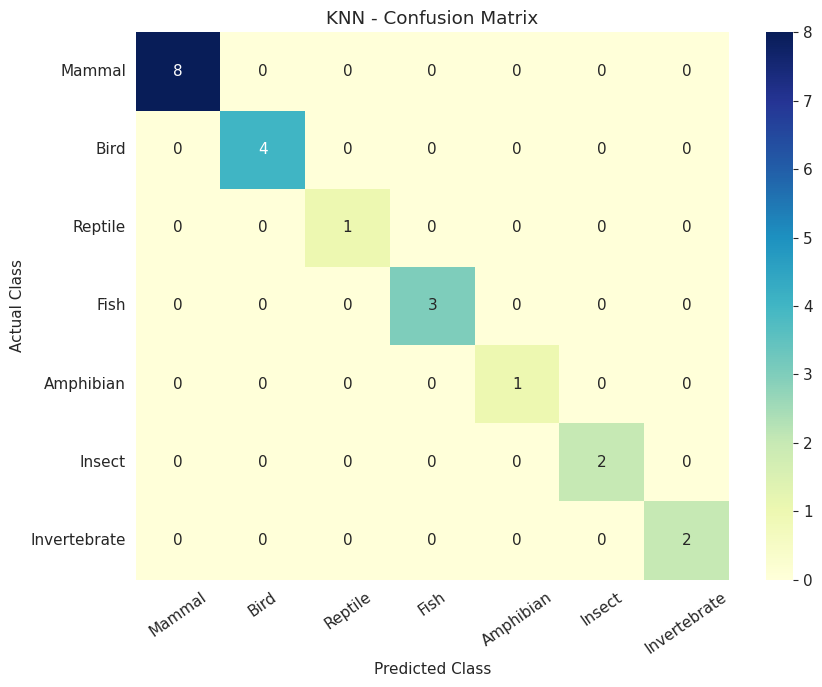


MODEL: SVM
Accuracy  : 100.00%
Precision : 100.00%
Recall    : 100.00%
F1 Score  : 100.00%
ROC AUC   : 98.57%

Classification Report:
              precision    recall  f1-score   support

      Mammal       1.00      1.00      1.00         8
        Bird       1.00      1.00      1.00         4
     Reptile       1.00      1.00      1.00         1
        Fish       1.00      1.00      1.00         3
   Amphibian       1.00      1.00      1.00         1
      Insect       1.00      1.00      1.00         2
Invertebrate       1.00      1.00      1.00         2

    accuracy                           1.00        21
   macro avg       1.00      1.00      1.00        21
weighted avg       1.00      1.00      1.00        21



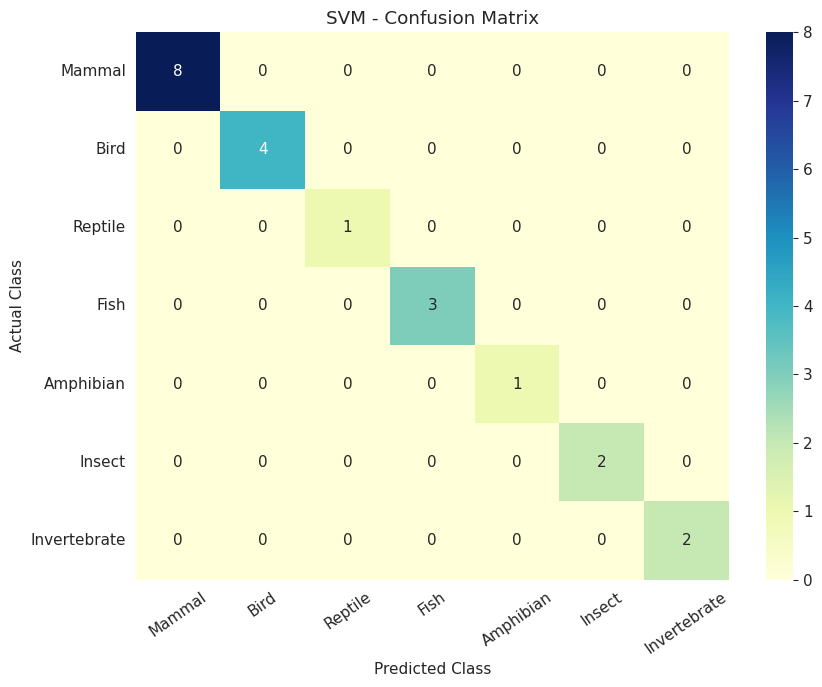


MODEL PERFORMANCE COMPARISON


,Model,Accuracy (%),Precision (%),Recall (%),F1 Score (%),ROC AUC (%)
0,Logistic Regression,100.00,100.00,100.00,100.00,100.00
1,Decision Tree,100.00,100.00,100.00,100.00,100.00
2,Random Forest,100.00,100.00,100.00,100.00,100.00
3,Gradient Boosting,100.00,100.00,100.00,100.00,100.00
4,Extra Trees,100.00,100.00,100.00,100.00,100.00
5,KNN,100.00,100.00,100.00,100.00,100.00
6,SVM,100.00,100.00,100.00,100.00,98.57
7,AdaBoost,85.71,78.57,85.71,80.95,98.53


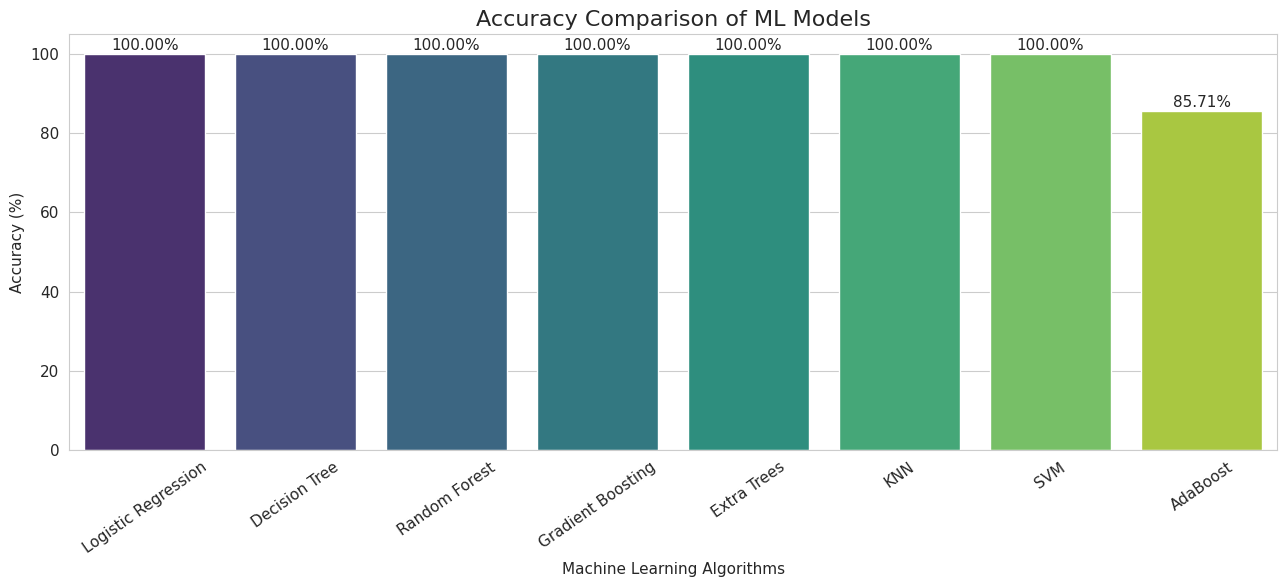

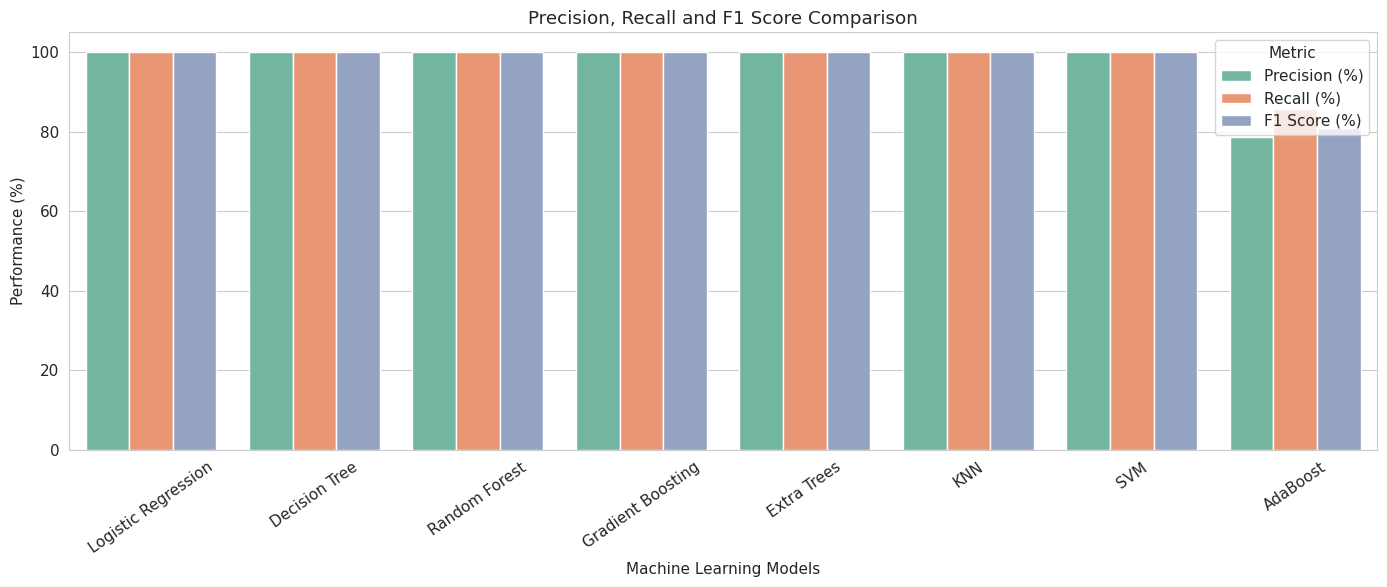

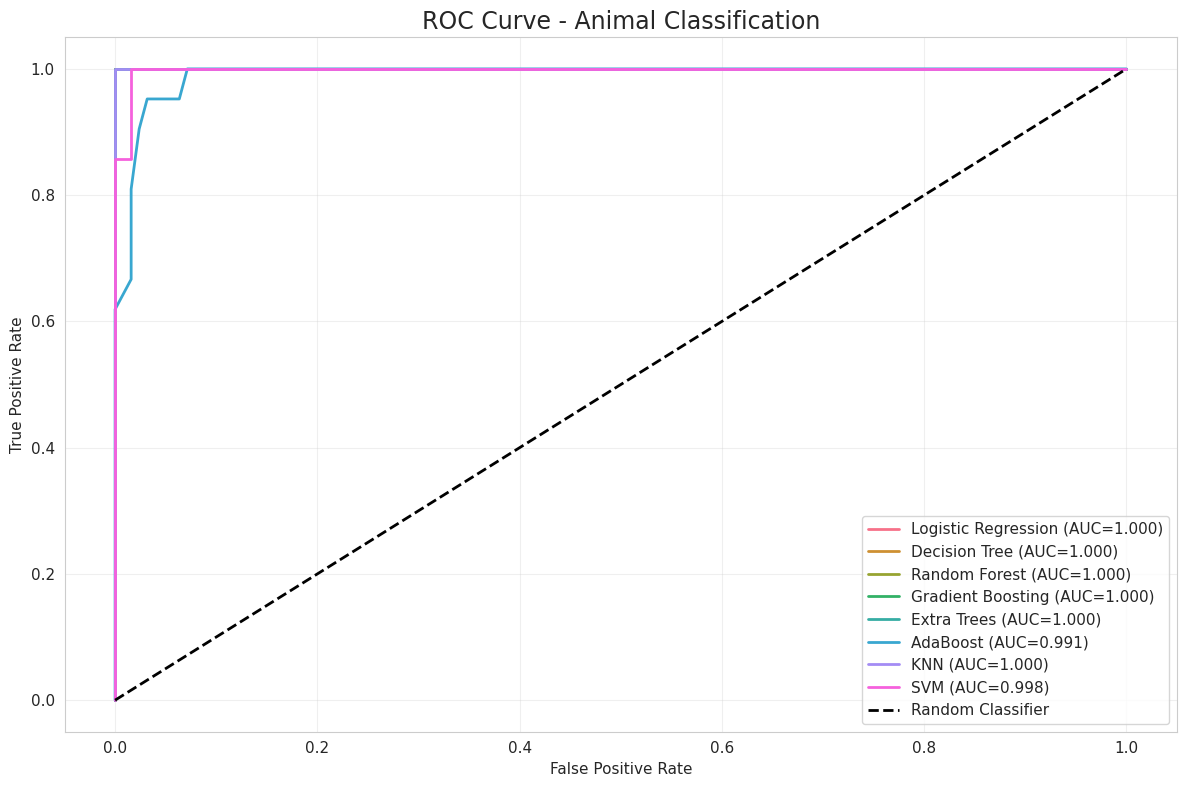

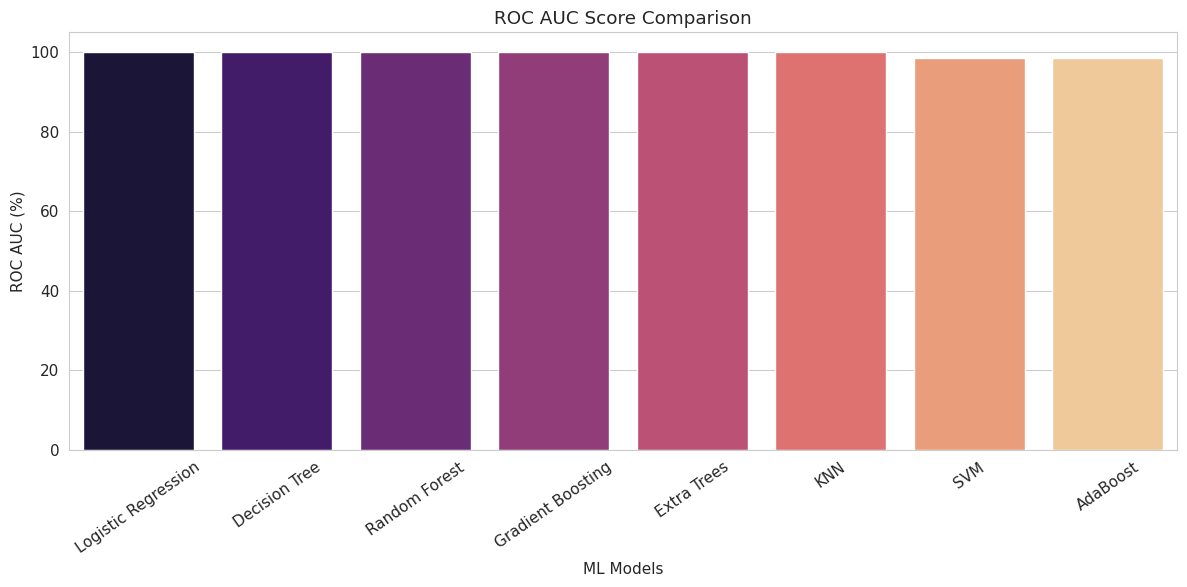


BEST MACHINE LEARNING MODEL
Best Model: Logistic Regression
Accuracy: 100.00%
Precision: 100.00%
Recall: 100.00%
F1 Score: 100.00%
ROC AUC: 100.00%

PROJECT COMPLETED SUCCESSFULLY
Total Animals: 101
Total Features: 16
Total Classes: 7
Training Records: 80
Testing Records: 21
Models Evaluated: 8
Best Algorithm: Logistic Regression

Animal Classification ML Pipeline Completed!


In [14]:

# ==============================================================
# ANIMAL CLASSIFICATION - COMPLETE MACHINE LEARNING PROJECT
# EDA + LABEL ENCODING + TRAIN TEST SPLIT + 8 ML ALGORITHMS
# ACCURACY + CONFUSION MATRIX + ROC CURVE + MODEL COMPARISON
# ==============================================================

# 1. IMPORT LIBRARIES

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier,
    ExtraTreesClassifier,
    AdaBoostClassifier
)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    roc_curve,
    auc,
    roc_auc_score
)

# ==============================================================
# 2. DATASET
# ==============================================================

df = df.copy()

print("=" * 65)
print("ANIMAL CLASSIFICATION DATASET")
print("=" * 65)

print("Dataset Shape:", df.shape)
display(df.head())

# ==============================================================
# 3. DATA CLEANING
# ==============================================================

df.columns = df.columns.str.strip().str.lower()

df.drop_duplicates(inplace=True)

df.replace([np.inf, -np.inf], np.nan, inplace=True)

# ==============================================================
# 4. CREATE ACTUAL ZOO CLASS LABELS
# ==============================================================

animal_class_mapping = {

    # 1 - Mammals
    'aardvark': 1, 'antelope': 1, 'bear': 1,
    'boar': 1, 'buffalo': 1, 'calf': 1,
    'cavy': 1, 'cheetah': 1, 'deer': 1,
    'dolphin': 1, 'elephant': 1, 'fruitbat': 1,
    'giraffe': 1, 'girl': 1, 'goat': 1,
    'gorilla': 1, 'hamster': 1, 'hare': 1,
    'leopard': 1, 'lion': 1, 'lynx': 1,
    'mink': 1, 'mole': 1, 'mongoose': 1,
    'opossum': 1, 'oryx': 1, 'platypus': 1,
    'polecat': 1, 'pony': 1, 'porpoise': 1,
    'puma': 1, 'pussycat': 1, 'raccoon': 1,
    'reindeer': 1, 'seal': 1, 'sealion': 1,
    'squirrel': 1, 'vampire': 1, 'vole': 1,
    'wallaby': 1, 'wolf': 1,

    # 2 - Birds
    'chicken': 2, 'crow': 2, 'dove': 2,
    'duck': 2, 'flamingo': 2, 'gull': 2,
    'hawk': 2, 'kiwi': 2, 'lark': 2,
    'ostrich': 2, 'parakeet': 2, 'penguin': 2,
    'pheasant': 2, 'rhea': 2, 'skimmer': 2,
    'skua': 2, 'sparrow': 2, 'swan': 2,
    'vulture': 2, 'wren': 2,

    # 3 - Reptiles
    'pitviper': 3, 'seasnake': 3, 'slowworm': 3,
    'tortoise': 3, 'tuatara': 3,

    # 4 - Fish
    'bass': 4, 'carp': 4, 'catfish': 4,
    'chub': 4, 'dogfish': 4, 'haddock': 4,
    'herring': 4, 'pike': 4, 'piranha': 4,
    'seahorse': 4, 'sole': 4, 'stingray': 4,
    'tuna': 4,

    # 5 - Amphibians
    'frog': 5, 'newt': 5, 'salamander': 5,
    'toad': 5,

    # 6 - Insects
    'flea': 6, 'gnat': 6, 'honeybee': 6,
    'housefly': 6, 'ladybird': 6, 'moth': 6,
    'termite': 6, 'wasp': 6,

    # 7 - Invertebrates
    'clam': 7, 'crab': 7, 'crayfish': 7,
    'lobster': 7, 'octopus': 7, 'scorpion': 7,
    'seawasp': 7, 'slug': 7, 'starfish': 7,
    'worm': 7
}

class_labels = {
    1: 'Mammal',
    2: 'Bird',
    3: 'Reptile',
    4: 'Fish',
    5: 'Amphibian',
    6: 'Insect',
    7: 'Invertebrate'
}

df['animal_name'] = (
    df['animal_name'].astype(str).str.strip().str.lower()
)

df['class_type'] = df['animal_name'].map(animal_class_mapping)

# Check unmapped animals
unmapped = df.loc[
    df['class_type'].isna(), 'animal_name'
].unique()

if len(unmapped) > 0:
    print("\nUnmapped Animals:", unmapped)

    raise ValueError(
        "Some animal names are not in the mapping. "
        "Check the animal names and update the mapping."
    )

df['class_type'] = df['class_type'].astype(int)

df['class_name'] = df['class_type'].map(class_labels)

print("\nAnimal Class Distribution:")
print(df['class_name'].value_counts())

# ==============================================================
# 5. DEFINE INPUT AND TARGET
# ==============================================================

# Remove animal_name and class_name from input features
X = df.drop(
    columns=['animal_name', 'class_type', 'class_name'],
    errors='ignore'
)

y = df['class_type']

print("\nInput Shape:", X.shape)
print("Target Shape:", y.shape)

print("\nInput Features:")
print(X.columns.tolist())

print("\nTarget Classes:")
print(y.value_counts().sort_index())

# ==============================================================
# 6. LABEL ENCODING
# ==============================================================

label_encoder = LabelEncoder()

y_encoded = label_encoder.fit_transform(y)

encoded_names = [
    class_labels[int(c)]
    for c in label_encoder.classes_
]

print("\nEncoded Target Labels:")

for i, name in enumerate(encoded_names):
    print(name, "=", i)

# ==============================================================
# 7. TRAIN TEST SPLITTING
# ==============================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_encoded,
    test_size=0.20,
    random_state=42,
    stratify=y_encoded
)

print("\nTraining Shape:", X_train.shape)
print("Testing Shape:", X_test.shape)

# ==============================================================
# 8. FEATURE PREPROCESSING
# ==============================================================

numerical_features = X.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X.select_dtypes(
    include=['object', 'category', 'bool']
).columns.tolist()

print("\nNumerical Features:", numerical_features)
print("Categorical Features:", categorical_features)

numerical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numerical_transformer, numerical_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)

# ==============================================================
# 9. MACHINE LEARNING ALGORITHMS
# ==============================================================

models = {

    'Logistic Regression': LogisticRegression(
        max_iter=3000
    ),

    'Decision Tree': DecisionTreeClassifier(
        random_state=42
    ),

    'Random Forest': RandomForestClassifier(
        n_estimators=200,
        random_state=42
    ),

    'Gradient Boosting': GradientBoostingClassifier(
        random_state=42
    ),

    'Extra Trees': ExtraTreesClassifier(
        n_estimators=200,
        random_state=42
    ),

    'AdaBoost': AdaBoostClassifier(
        n_estimators=100,
        random_state=42
    ),

    'KNN': KNeighborsClassifier(
        n_neighbors=3
    ),

    'SVM': SVC(
        probability=True,
        random_state=42
    )
}

# ==============================================================
# 10. TRAIN AND EVALUATE MODELS
# ==============================================================

results = []
trained_models = {}
roc_data = {}

n_classes = len(label_encoder.classes_)

# One-vs-rest target format for multiclass ROC
y_test_binary = np.column_stack([
    (y_test == i).astype(int)
    for i in range(n_classes)
])

for name, model in models.items():

    print("\n" + "=" * 65)
    print("MODEL:", name)
    print("=" * 65)

    pipeline = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('classifier', model)
    ])

    # Model training
    pipeline.fit(X_train, y_train)

    # Predictions
    y_pred = pipeline.predict(X_test)

    y_prob = pipeline.predict_proba(X_test)

    # Evaluation metrics
    accuracy = accuracy_score(y_test, y_pred) * 100

    precision = precision_score(
        y_test, y_pred,
        average='weighted',
        zero_division=0
    ) * 100

    recall = recall_score(
        y_test, y_pred,
        average='weighted',
        zero_division=0
    ) * 100

    f1 = f1_score(
        y_test, y_pred,
        average='weighted',
        zero_division=0
    ) * 100

    # Multiclass ROC AUC
    auc_score = roc_auc_score(
        y_test,
        y_prob,
        multi_class='ovr',
        average='macro'
    ) * 100

    # Store model
    trained_models[name] = pipeline

    # Store evaluation results
    results.append({
        'Model': name,
        'Accuracy (%)': accuracy,
        'Precision (%)': precision,
        'Recall (%)': recall,
        'F1 Score (%)': f1,
        'ROC AUC (%)': auc_score
    })

    # Micro-average ROC curve
    fpr, tpr, _ = roc_curve(
        y_test_binary.ravel(),
        y_prob.ravel()
    )

    roc_data[name] = {
        'fpr': fpr,
        'tpr': tpr,
        'auc': auc(fpr, tpr)
    }

    print(f"Accuracy  : {accuracy:.2f}%")
    print(f"Precision : {precision:.2f}%")
    print(f"Recall    : {recall:.2f}%")
    print(f"F1 Score  : {f1:.2f}%")
    print(f"ROC AUC   : {auc_score:.2f}%")

    # Classification report
    print("\nClassification Report:")

    print(classification_report(
        y_test,
        y_pred,
        labels=np.arange(n_classes),
        target_names=encoded_names,
        zero_division=0
    ))

    # Confusion Matrix
    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=np.arange(n_classes)
    )

    plt.figure(figsize=(9, 7))

    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='YlGnBu',
        xticklabels=encoded_names,
        yticklabels=encoded_names
    )

    plt.title(f'{name} - Confusion Matrix')
    plt.xlabel('Predicted Class')
    plt.ylabel('Actual Class')
    plt.xticks(rotation=35)
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.show()

# ==============================================================
# 11. MODEL COMPARISON TABLE
# ==============================================================

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by='Accuracy (%)',
    ascending=False
).reset_index(drop=True)

print("\n" + "=" * 65)
print("MODEL PERFORMANCE COMPARISON")
print("=" * 65)

display(results_df.round(2))

# ==============================================================
# 12. ACCURACY COMPARISON
# ==============================================================

plt.figure(figsize=(13, 6))

sns.barplot(
    data=results_df,
    x='Model',
    y='Accuracy (%)',
    hue='Model',
    palette='viridis',
    legend=False
)

plt.title('Accuracy Comparison of ML Models', fontsize=16)
plt.xlabel('Machine Learning Algorithms')
plt.ylabel('Accuracy (%)')
plt.xticks(rotation=35)
plt.ylim(0, 105)

for i, value in enumerate(results_df['Accuracy (%)']):
    plt.text(i, value + 1, f'{value:.2f}%', ha='center')

plt.tight_layout()
plt.show()

# ==============================================================
# 13. PRECISION RECALL F1 COMPARISON
# ==============================================================

metrics_df = results_df.melt(
    id_vars='Model',
    value_vars=[
        'Precision (%)',
        'Recall (%)',
        'F1 Score (%)'
    ],
    var_name='Metric',
    value_name='Score'
)

plt.figure(figsize=(14, 6))

sns.barplot(
    data=metrics_df,
    x='Model',
    y='Score',
    hue='Metric',
    palette='Set2'
)

plt.title('Precision, Recall and F1 Score Comparison')
plt.ylabel('Performance (%)')
plt.xlabel('Machine Learning Models')
plt.xticks(rotation=35)
plt.tight_layout()
plt.show()

# ==============================================================
# 14. ROC CURVE - ALL MODELS
# ==============================================================

plt.figure(figsize=(12, 8))

roc_colors = sns.color_palette(
    'husl',
    len(roc_data)
)

for (name, data), color in zip(roc_data.items(), roc_colors):

    plt.plot(
        data['fpr'],
        data['tpr'],
        linewidth=2,
        color=color,
        label=f"{name} (AUC={data['auc']:.3f})"
    )

plt.plot(
    [0, 1],
    [0, 1],
    'k--',
    linewidth=2,
    label='Random Classifier'
)

plt.title('ROC Curve - Animal Classification', fontsize=17)
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend(loc='lower right')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# ==============================================================
# 15. ROC AUC COMPARISON
# ==============================================================

plt.figure(figsize=(12, 6))

sns.barplot(
    data=results_df,
    x='Model',
    y='ROC AUC (%)',
    hue='Model',
    palette='magma',
    legend=False
)

plt.title('ROC AUC Score Comparison')
plt.xlabel('ML Models')
plt.ylabel('ROC AUC (%)')
plt.xticks(rotation=35)
plt.tight_layout()
plt.show()

# ==============================================================
# 16. BEST MODEL
# ==============================================================

best_model_name = results_df.iloc[0]['Model']

best_model = trained_models[best_model_name]

print("\n" + "=" * 65)
print("BEST MACHINE LEARNING MODEL")
print("=" * 65)

print("Best Model:", best_model_name)

print(
    "Accuracy:",
    f"{results_df.iloc[0]['Accuracy (%)']:.2f}%"
)

print(
    "Precision:",
    f"{results_df.iloc[0]['Precision (%)']:.2f}%"
)

print(
    "Recall:",
    f"{results_df.iloc[0]['Recall (%)']:.2f}%"
)

print(
    "F1 Score:",
    f"{results_df.iloc[0]['F1 Score (%)']:.2f}%"
)

print(
    "ROC AUC:",
    f"{results_df.iloc[0]['ROC AUC (%)']:.2f}%"
)

# ==============================================================
# 17. FINAL SUMMARY
# ==============================================================

print("\n" + "=" * 65)
print("PROJECT COMPLETED SUCCESSFULLY")
print("=" * 65)

print("Total Animals:", len(df))
print("Total Features:", X.shape[1])
print("Total Classes:", n_classes)
print("Training Records:", len(X_train))
print("Testing Records:", len(X_test))
print("Models Evaluated:", len(trained_models))
print("Best Algorithm:", best_model_name)

print("\nAnimal Classification ML Pipeline Completed!")


## Thank you..pls upvote!!!!!!!!!